# BC Card Commercial Area Diagnosis Based on Foreign Consumer Spending Structure — Complete Analysis Notebook

This notebook starts with the raw BC competition data and reproduces the following analyses from beginning to end.

1. Data structure and quality EDA
2. Calculation of domestic vs foreign industry spending structure differences (TVD)
3. Classification into 4 Structure types based on `Scale × TVD`
4. H1/H2 Structure robustness validation
5. CNT·ATV-based Momentum
6. High/Medium/Low Confidence based on time-window (2-month/3-month) robustness
7. Integration of Ministry of Justice registered foreigners and Ministry of the Interior and Safety resident population data across all 255 regions
8. External validation A: Convergence between BC foreign spending scale and the distribution of registered foreigners
9. External validation B: External validity of TVD — Pearson/Spearman, tertiles, Mann–Whitney
10. Representative cases: Even key foreign spending regions differ in structure
11. Residual analysis: Foreign card spending unexplained by registered foreigner counts
12. Integration of Korea Tourism Organization 2026H1 visitor data and External Context (resident-dominant·mixed·visitor-dominant)
13. Generation of the final Action Matrix
14. Proposal for the LLM Action Layer
15. Final decision-making framework
16. Final conclusions

> Core principle: Structure decisions in the order **Data → Validated Labels → Evidence → Action**.


In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr, mannwhitneyu, kruskal
from sklearn.metrics import cohen_kappa_score
import statsmodels.api as sm

pd.set_option('display.max_columns', 100)
pd.set_option('display.float_format', lambda x: f'{x:,.6f}')

BASE = Path('..')
RAW_PATH = BASE/'02_data/raw/ABP_CONTEST_DATA.csv'
MOJ_PATH = BASE/'02_data/external/MOJ_registered_foreigners_202606_255.csv'
POP_PATH = BASE/'02_data/external/MOIS_resident_population_202606_255.csv'

KTO_RAW_PATH = BASE/'02_data/external/KTO_visitors_2026H1_raw.csv'
EXT_JOINED_PATH = BASE/'02_data/external/external_validation_255_joined.csv'


# Korean-capable font configuration for all charts (Windows / macOS / Linux)
# Prefer installed fonts; otherwise download once from the official Noto repository.
import matplotlib.font_manager as _fm
from matplotlib.ft2font import FT2Font as _FT2Font
import urllib.request as _urlrequest

def _configure_korean_font():
    _names = ("Malgun Gothic", "AppleGothic", "NanumGothic",
              "Noto Sans CJK KR", "Noto Sans KR", "Noto Sans CJK JP")
    _required = set(map(ord, "\ud55c\uae00\uc678\uad6d\uc778\uc18c\ube44\uad6c\uc870\uac70\ub798\uac74\uc218\uc804\uccb4\ube44\uc911\uac1c\uc6d4\uc815\uc8fc\ubc29\ubb38\uac1d\ub2e8\uac00\uc601\uc554\uc81c\uc8fc\uc2dc\ub4f1\ub85d"))

    def _register(_path):
        _path = Path(_path)
        if not _path.is_file():
            return None
        try:
            if not _required.issubset(_FT2Font(str(_path)).get_charmap()):
                return None
            _fm.fontManager.addfont(str(_path))
            return _fm.FontProperties(fname=str(_path)).get_name()
        except (OSError, RuntimeError, ValueError):
            return None

    # Use OS-installed fonts to minimize additional font installation.
    _entries = list(_fm.fontManager.ttflist)
    _selected = None
    for _name in _names:
        for _entry in _entries:
            if _entry.name == _name:
                _selected = _register(_entry.fname)
                if _selected:
                    break
        if _selected:
            break

    # Use a project font or a font cached by a previous run
    _cache_font = Path.home() / ".cache" / "bc-analysis" / "fonts" / "NotoSansCJKkr-Regular.otf"
    if not _selected:
        for _path in (Path("fonts/NotoSansCJKkr-Regular.otf"),
                      Path("../fonts/NotoSansCJKkr-Regular.otf"), _cache_font):
            _selected = _register(_path)
            if _selected:
                break

    if not _selected:
        _url = ("https://raw.githubusercontent.com/notofonts/noto-cjk/main/"
                "Sans/OTF/Korean/NotoSansCJKkr-Regular.otf")
        _cache_font.parent.mkdir(parents=True, exist_ok=True)
        _temp_font = _cache_font.with_suffix(".download")
        try:
            with _urlrequest.urlopen(_url, timeout=30) as _response:
                _temp_font.write_bytes(_response.read())
            if not _required.issubset(_FT2Font(str(_temp_font)).get_charmap()):
                raise RuntimeError("Unable to verify Korean glyphs in the downloaded font.")
            _temp_font.replace(_cache_font)
            _selected = _register(_cache_font)
        except Exception as _error:
            _temp_font.unlink(missing_ok=True)
            raise RuntimeError(
                "No Korean-capable font was found. Install Malgun Gothic/NanumGothic/Noto Sans CJK KR and "
                "restart the kernel, or place NotoSansCJKkr-Regular.otf in the fonts folder. "
                "An internet connection is required for automatic downloading."
            ) from _error

    plt.rcParams.update({
        "font.family": [_selected],
        "axes.unicode_minus": False,
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
    })
    print(f"Korean-capable chart font: {_selected}")
    return _selected

KOREAN_FONT = _configure_korean_font()


from matplotlib.ticker import PercentFormatter
from cycler import cycler
COLORS=dict(blue='#3569C8',teal='#168A82',orange='#E69B38',purple='#8960B5',ink='#25344B',muted='#718096')
STRUCTURE_COLORS={'Large · High divergence':COLORS['purple'],'Large · Low divergence':COLORS['blue'],
                  'Small · High divergence':COLORS['orange'],'Small · Low divergence':COLORS['teal']}
CONTEXT_COLORS={'Resident-dominant':COLORS['purple'],'Mixed':COLORS['teal'],'Visitor-dominant':COLORS['orange']}
plt.rcParams.update({
    'figure.facecolor':'#F4F7FC','axes.facecolor':'white','figure.dpi':130,'savefig.dpi':180,
    'figure.constrained_layout.use':True,'axes.prop_cycle':cycler(color=list(STRUCTURE_COLORS.values())),
    'axes.spines.top':False,'axes.spines.right':False,'axes.edgecolor':'#D9E1ED',
    'axes.labelcolor':COLORS['ink'],'axes.titlecolor':COLORS['ink'],'axes.titleweight':'bold',
    'axes.titlesize':16,'axes.titlepad':20,'axes.labelsize':11,'xtick.color':'#526177',
    'ytick.color':'#526177','xtick.labelsize':10,'ytick.labelsize':10,'grid.color':'#DCE4EF',
    'grid.linewidth':.7,'legend.frameon':False,'legend.fontsize':10,'lines.linewidth':2.3,
})
def style_axes(ax,title,xlabel,ylabel,grid='both'):
    ax.set(title=title,xlabel=xlabel,ylabel=ylabel)
    ax.set_axisbelow(True)
    ax.grid(axis=grid,alpha=.8)
    ax.tick_params(length=0,pad=8)
    ax.margins(x=.08,y=.13)
def category_scatter(ax,x,y,groups,palette):
    for name,color in palette.items():
        mask=groups.eq(name)
        if mask.any():
            ax.scatter(x.loc[mask],y.loc[mask],s=48,c=color,alpha=.76,
                       edgecolors='white',linewidths=.55,label=f'{name} (n={int(mask.sum())})',zorder=3)
def legend_below(ax,ncol=2,title=None):
    ax.legend(loc='upper center',bbox_to_anchor=(.5,-.18),ncol=ncol,title=title,
              columnspacing=1.6,handletextpad=.6)
def note(ax,text):
    ax.text(.025,.97,text,transform=ax.transAxes,va='top',fontsize=10,color=COLORS['ink'],zorder=7,
            bbox=dict(boxstyle='round,pad=.55',fc='#F4F7FC',ec='#E0E7F1',alpha=.96))
def label_region(ax,name,x,y,offset=(10,12)):
    ax.scatter([x],[y],s=83,facecolors='none',edgecolors=COLORS['ink'],linewidths=1.1,zorder=5)
    ax.annotate(_english_text(name.split(' ')[-1]),(x,y),xytext=offset,textcoords='offset points',fontsize=9,
                color=COLORS['ink'],ha='left' if offset[0]>=0 else 'right',
                bbox=dict(boxstyle='round,pad=.28',fc='white',ec='#D9E1ED',alpha=.96),
                arrowprops=dict(arrowstyle='-',color='#8291A6',lw=.8),zorder=6)


_EN_DISPLAY = {'\uc804\uccb4 \uac70\ub798\uac74\uc218 (\ubc31\ub9cc\uac74)': 'Total transactions (millions)', '2026\ub144 \uc0c1\ubc18\uae30 \uc6d4\ubcc4 \uac70\ub798\uac74\uc218': 'Monthly Transactions in the First Half of 2026', '\uc804\uccb4 \uac70\ub798\uac74\uc218': 'Total transactions', '\ucd5c\ub2e4 \uac70\ub798 \uc6d4': 'Peak transaction month', '2026\ub144': '2026', 'Structure · \uc0c1\uad8c \uaddc\ubaa8\uc640 \uc18c\ube44\uad6c\uc870 \ucc28\uc774': 'Structure · Market Scale and Spending Divergence', '\uc804\uad6d \uc804\uccb4 \uac70\ub798\uac74\uc218 \ube44\uc911 (\ub85c\uadf8 \ub208\uae08)': 'Share of all nationwide transactions (log scale)', 'TVD · \ub0b4·\uc678\uad6d\uc778 \uc18c\ube44\uad6c\uc870 \uad34\ub9ac': 'TVD · Domestic–foreign spending divergence', '\uc810\uc120: \uc804\uad6d \uc911\uc559\uac12': 'Dashed lines: nationwide medians', 'Structure 4\uc720\ud615': 'Four Structure types', '\ub4f1\ub85d\uc678\uad6d\uc778 \uaddc\ubaa8\uc640 BC \uc678\uad6d\uc778 \uc18c\ube44\uaddc\ubaa8': 'Registered Foreigners and BC Foreign Spending', 'log1p(\ub4f1\ub85d\uc678\uad6d\uc778 \uc218)': 'log1p(Registered foreigners)', 'log1p(BC \uc678\uad6d\uc778 \uc774\uc6a9\uae08\uc561)': 'log1p(BC foreign spending)', '\uc804\uccb4 \uc9c0\uc5ed OLS \ucd94\uc138\uc120': 'OLS trend · all regions', '\uc18c\ube44\uad6c\uc870 \uad34\ub9ac\uc640 \ub4f1\ub85d\uae30\ubc18 \uc678\uad6d\uc778 \ube44\uc728': 'Spending Divergence and Registered Foreigner Share', '\ub4f1\ub85d\uae30\ubc18 \uc678\uad6d\uc778 \ube44\uc728': 'Registered foreigner share', '\uc810\uc120: TVD \uc0bc\ubd84\uc704 \uacbd\uacc4': 'Dashed lines: TVD tertile boundaries', 'TVD \uc0bc\ubd84\uc704': 'TVD tertiles', '\ubc29\ubb38·\uc815\uc8fc \ub9e5\ub77d\uacfc BC \uc678\uad6d\uc778 \uc18c\ube44\uc794\ucc28': 'Visitor–Resident Context and BC Foreign Spending Residuals', 'ContextGap · \ubc29\ubb38 \ubc31\ubd84\uc704 - \uc815\uc8fc \ubc31\ubd84\uc704': 'ContextGap · Visitor percentile - resident percentile', '\ub4f1\ub85d\uc678\uad6d\uc778 \uaddc\ubaa8 \ub300\ube44 \uc18c\ube44\uc794\ucc28 (log1p \uae08\uc561)': 'Spending residual vs registered foreigners (log1p amount)', '\uc804\uccb4 \uc9c0\uc5ed \uc120\ud615 \ucd94\uc138': 'Linear trend · all regions', '\uc74c\uc601 \uacbd\uacc4: ContextGap \uc0bc\ubd84\uc704': 'Shading boundaries: ContextGap tertiles', '\ub300\uaddc\ubaa8·\uace0\uad34\ub9ac': 'Large · High divergence', '\ub300\uaddc\ubaa8·\uc800\uad34\ub9ac': 'Large · Low divergence', '\uc18c\uaddc\ubaa8·\uace0\uad34\ub9ac': 'Small · High divergence', '\uc18c\uaddc\ubaa8·\uc800\uad34\ub9ac': 'Small · Low divergence', '\uc815\uc8fc\uc6b0\uc138\ud615': 'Resident-dominant', '\ud63c\ud569\ud615': 'Mixed', '\ubc29\ubb38\uc6b0\uc138\ud615': 'Visitor-dominant', '\uc9c0\uc5ed \uc218': 'Number of regions', '\uc6d4 \uc218': 'Number of months', '\uc5c5\uc885 \uc218': 'Number of industries', '\uacb0\uce21 \uc140': 'Missing cells', 'cnt \ucd5c\uc18c\uac12': 'Minimum cnt', 'amt 1\ub9cc\uc6d0 \ub2e8\uc704 \ube44\uc728': 'Share of amt in KRW 10,000 units', '\uc5c5\uc885:': 'Industries:', '\uac1c\uc778\uc18c\ube44 \uc911 \uc678\uad6d\uc778 \uae08\uc561 \ube44\uc911:': 'Foreign spending share of personal consumption:', '\uac1c\uc778\uc18c\ube44 \uc911 \uc678\uad6d\uc778 \uac70\ub798\uac74\uc218 \ube44\uc911:': 'Foreign transaction share of personal consumption:', 'Structure \uc77c\uce58\uc728': 'Structure agreement rate', '\uac01 \ubc18\uae30 \uc678\uad6d\uc778 CNT \ucd5c\uc18c': 'Minimum foreign CNT in each half', 'CNT/ATV \ubc29\ud5a5 \ubaa8\ub450 \uc720\uc9c0:': 'Both CNT/ATV directions maintained:', '\ucd5c\uc885 \uc870\uc778:': 'Final join:', '\uacb0\uce21:': 'Missing values:', '\uc800\uad34\ub9ac \uc911\uc559\uac12:': 'Low-divergence median:', '\uace0\uad34\ub9ac \uc911\uc559\uac12:': 'High-divergence median:', '\uc911\uc559\uac12 \ubc30\uc218:': 'Median ratio:', '\uc591(+) \uc794\ucc28 \uc0c1\uc704': 'Largest positive (+) residuals', '\uc74c(-) \uc794\ucc28 \ud558\uc704': 'Most negative (-) residuals', '\uac70\ub798·\uac1d\ub2e8\uac00 \ub3d9\ubc18 \uc0c1\uc2b9': 'Transactions and ATV both rising', '\uac70\ub798 \ud655\ub300': 'Transaction expansion', '\uac1d\ub2e8\uac00 \uc0c1\uc2b9': 'ATV rising', '\ub3d9\ubc18 \uc57d\ud654': 'Both weakening', '\uadf8\ub798\ud504 \ud55c\uae00 \ud3f0\ud2b8:': 'Korean-capable chart font:', '\ub0b4\ub824\ubc1b\uc740 \ud3f0\ud2b8\uc758 \ud55c\uae00 \uae00\ub9ac\ud504\ub97c \ud655\uc778\ud560 \uc218 \uc5c6\uc2b5\ub2c8\ub2e4.': 'Unable to verify Korean glyphs in the downloaded font.', '\ud55c\uae00 \ud3f0\ud2b8\ub97c \ucc3e\uc9c0 \ubabb\ud588\uc2b5\ub2c8\ub2e4. \ub9d1\uc740 \uace0\ub515/\ub098\ub214\uace0\ub515/Noto Sans CJK KR\uc744 \uc124\uce58\ud55c \ub4a4 ': 'No Korean-capable font was found. Install Malgun Gothic/NanumGothic/Noto Sans CJK KR and ', '\ucee4\ub110\uc744 \uc7ac\uc2dc\uc791\ud558\uac70\ub098, NotoSansCJKkr-Regular.otf\ub97c fonts \ud3f4\ub354\uc5d0 \ub123\uc5b4\uc8fc\uc138\uc694. ': 'restart the kernel, or place NotoSansCJKkr-Regular.otf in the fonts folder. ', '\uc790\ub3d9 \ub2e4\uc6b4\ub85c\ub4dc\ub97c \uc0ac\uc6a9\ud560 \ub54c\ub294 \uc778\ud130\ub137 \uc5f0\uacb0\uc774 \ud544\uc694\ud569\ub2c8\ub2e4.': 'An internet connection is required for automatic downloading.', '\ubaa8\ub4e0 \uadf8\ub798\ud504\uc5d0 \uc801\uc6a9\ub418\ub294 \ud55c\uae00 \ud3f0\ud2b8 \uc124\uc815 (Windows / macOS / Linux)': 'Korean-capable font configuration for all charts (Windows / macOS / Linux)', '\uc124\uce58\ub41c \ud3f0\ud2b8\ub97c \uc6b0\uc120 \uc0ac\uc6a9\ud569\ub2c8\ub2e4. \uc5c6\uc73c\uba74 Noto \uacf5\uc2dd \uc800\uc7a5\uc18c\uc5d0\uc11c \ucd5c\ucd08 1\ud68c \ub0b4\ub824\ubc1b\uc2b5\ub2c8\ub2e4.': 'Prefer installed fonts; otherwise download once from the official Noto repository.', 'OS\uc5d0 \uc124\uce58\ub41c \ud3f0\ud2b8 \uc0ac\uc6a9: \uc0ac\uc6a9\uc790 \ud658\uacbd\uc758 \ubcc4\ub3c4 \ud3f0\ud2b8 \uc124\uce58\ub97c \ucd5c\ub300\ud55c \ud53c\ud569\ub2c8\ub2e4.': 'Use OS-installed fonts to minimize additional font installation.', '\ud504\ub85c\uc81d\ud2b8 \ud3f0\ud2b8 \ub610\ub294 \uc774\uc804 \uc2e4\ud589\uc5d0\uc11c \uc800\uc7a5\ub41c \ud3f0\ud2b8 \uc0ac\uc6a9': 'Use a project font or a font cached by a previous run', '\uac74\uc218 \uae30\uc900 TVD: robustness': 'Count-based TVD: robustness', '\ub4f1\ub85d\uc678\uad6d\uc778 \uaddc\ubaa8\ub9cc\uc73c\ub85c \uc124\uba85\ub418\ub294 BC \uc678\uad6d\uc778 \uc18c\ube44 \uae30\ub300\uac12\uc758 \uc794\ucc28': 'Residuals from expected BC foreign spending explained solely by registered foreigner scale', '\uc608\uc2dc: LLM\uc5d0 \ub118\uae38 \uc81c\uc8fc \uc9c4\ub2e8 \ud328\ud0b7': 'Example: Jeju diagnostic packet passed to the LLM', '12\uc7a5\uc5d0\uc11c \ud310\uc815\ud55c External Context': 'External Context classified in Section 12', '12\uc7a5 External Context \ud310\uc815 \uacb0\uacfc (KTO 2026H1 + \ub4f1\ub85d\uc678\uad6d\uc778 \ube44\uc728, \uc5c4\uaca9\ud45c\ubcf8 \uae30\uc900)': 'Section 12 External Context classification (KTO 2026H1 + registered foreigner share, strict sample)', '\uc11c\uc6b8\ud2b9\ubcc4\uc2dc': 'Seoul', '\ubd80\uc0b0\uad11\uc5ed\uc2dc': 'Busan', '\ub300\uad6c\uad11\uc5ed\uc2dc': 'Daegu', '\uc778\ucc9c\uad11\uc5ed\uc2dc': 'Incheon', '\uad11\uc8fc\uad11\uc5ed\uc2dc': 'Gwangju', '\ub300\uc804\uad11\uc5ed\uc2dc': 'Daejeon', '\uc6b8\uc0b0\uad11\uc5ed\uc2dc': 'Ulsan', '\uc138\uc885\ud2b9\ubcc4\uc790\uce58\uc2dc': 'Sejong', '\uacbd\uae30\ub3c4': 'Gyeonggi-do', '\uac15\uc6d0\ud2b9\ubcc4\uc790\uce58\ub3c4': 'Gangwon-do', '\ucda9\uccad\ubd81\ub3c4': 'Chungcheongbuk-do', '\ucda9\uccad\ub0a8\ub3c4': 'Chungcheongnam-do', '\uc804\ubd81\ud2b9\ubcc4\uc790\uce58\ub3c4': 'Jeonbuk-do', '\uc804\ub77c\ub0a8\ub3c4': 'Jeollanam-do', '\uacbd\uc0c1\ubd81\ub3c4': 'Gyeongsangbuk-do', '\uacbd\uc0c1\ub0a8\ub3c4': 'Gyeongsangnam-do', '\uc81c\uc8fc\ud2b9\ubcc4\uc790\uce58\ub3c4': 'Jeju-do', '\uc2dc': '-si', '\uad70': '-gun', '\uad6c': '-gu', '\uac15\uc6d0\ud2b9\ubcc4\uc790\uce58\ub3c4 \uace0\uc131\uad70': 'Gangwon-do Goseong-gun', '\uc11c\uc6b8': 'Seoul', '\ubd80\uc0b0': 'Busan', '\ub300\uad6c': 'Daegu', '\uc778\ucc9c': 'Incheon', '\uad11\uc8fc': 'Gwangju', '\ub300\uc804': 'Daejeon', '\uc6b8\uc0b0': 'Ulsan', '\uac15\uc6d0': 'Gangwon', '\uacbd\uae30': 'Gyeonggi', '\ucda9\ubd81': 'Chungbuk', '\ucda9\ub0a8': 'Chungnam', '\uc804\ubd81': 'Jeonbuk', '\uc804\ub0a8': 'Jeonnam', '\uacbd\ubd81': 'Gyeongbuk', '\uacbd\ub0a8': 'Gyeongnam', '\uc81c\uc8fc': 'Jeju', '\uac15\ub989\uc2dc': 'Gangneung-si', '\uac15\ub989\uad70': 'Gangneung-gun', '\uac15\ub989\uad6c': 'Gangneung-gu', '\uace0\uc131\uc2dc': 'Goseong-si', '\uace0\uc131\uad70': 'Goseong-gun', '\uace0\uc131\uad6c': 'Goseong-gu', '\ub3d9\ud574\uc2dc': 'Donghae-si', '\ub3d9\ud574\uad70': 'Donghae-gun', '\ub3d9\ud574\uad6c': 'Donghae-gu', '\uc0bc\ucc99\uc2dc': 'Samcheok-si', '\uc0bc\ucc99\uad70': 'Samcheok-gun', '\uc0bc\ucc99\uad6c': 'Samcheok-gu', '\uc18d\ucd08\uc2dc': 'Sokcho-si', '\uc18d\ucd08\uad70': 'Sokcho-gun', '\uc18d\ucd08\uad6c': 'Sokcho-gu', '\uc591\uad6c\uc2dc': 'Yanggu-si', '\uc591\uad6c\uad70': 'Yanggu-gun', '\uc591\uad6c\uad6c': 'Yanggu-gu', '\uc591\uc591\uc2dc': 'Yangyang-si', '\uc591\uc591\uad70': 'Yangyang-gun', '\uc591\uc591\uad6c': 'Yangyang-gu', '\uc601\uc6d4\uc2dc': 'Yeongwol-si', '\uc601\uc6d4\uad70': 'Yeongwol-gun', '\uc601\uc6d4\uad6c': 'Yeongwol-gu', '\uc6d0\uc8fc\uc2dc': 'Wonju-si', '\uc6d0\uc8fc\uad70': 'Wonju-gun', '\uc6d0\uc8fc\uad6c': 'Wonju-gu', '\uc778\uc81c\uc2dc': 'Inje-si', '\uc778\uc81c\uad70': 'Inje-gun', '\uc778\uc81c\uad6c': 'Inje-gu', '\uc815\uc120\uc2dc': 'Jeongseon-si', '\uc815\uc120\uad70': 'Jeongseon-gun', '\uc815\uc120\uad6c': 'Jeongseon-gu', '\ucca0\uc6d0\uc2dc': 'Cheorwon-si', '\ucca0\uc6d0\uad70': 'Cheorwon-gun', '\ucca0\uc6d0\uad6c': 'Cheorwon-gu', '\ucd98\ucc9c\uc2dc': 'Chuncheon-si', '\ucd98\ucc9c\uad70': 'Chuncheon-gun', '\ucd98\ucc9c\uad6c': 'Chuncheon-gu', '\ud0dc\ubc31\uc2dc': 'Taebaek-si', '\ud0dc\ubc31\uad70': 'Taebaek-gun', '\ud0dc\ubc31\uad6c': 'Taebaek-gu', '\ud3c9\ucc3d\uc2dc': 'Pyeongchang-si', '\ud3c9\ucc3d\uad70': 'Pyeongchang-gun', '\ud3c9\ucc3d\uad6c': 'Pyeongchang-gu', '\ud64d\ucc9c\uc2dc': 'Hongcheon-si', '\ud64d\ucc9c\uad70': 'Hongcheon-gun', '\ud64d\ucc9c\uad6c': 'Hongcheon-gu', '\ud654\ucc9c\uc2dc': 'Hwacheon-si', '\ud654\ucc9c\uad70': 'Hwacheon-gun', '\ud654\ucc9c\uad6c': 'Hwacheon-gu', '\ud6a1\uc131\uc2dc': 'Hoengseong-si', '\ud6a1\uc131\uad70': 'Hoengseong-gun', '\ud6a1\uc131\uad6c': 'Hoengseong-gu', '\uac00\ud3c9\uc2dc': 'Gapyeong-si', '\uac00\ud3c9\uad70': 'Gapyeong-gun', '\uac00\ud3c9\uad6c': 'Gapyeong-gu', '\uace0\uc591\uc2dc': 'Goyang-si', '\uace0\uc591\uad70': 'Goyang-gun', '\uace0\uc591\uad6c': 'Goyang-gu', '\ub355\uc591\uc2dc': 'Deogyang-si', '\ub355\uc591\uad70': 'Deogyang-gun', '\ub355\uc591\uad6c': 'Deogyang-gu', '\uc77c\uc0b0\ub3d9\uc2dc': 'Ilsandong-si', '\uc77c\uc0b0\ub3d9\uad70': 'Ilsandong-gun', '\uc77c\uc0b0\ub3d9\uad6c': 'Ilsandong-gu', '\uc77c\uc0b0\uc11c\uc2dc': 'Ilsanseo-si', '\uc77c\uc0b0\uc11c\uad70': 'Ilsanseo-gun', '\uc77c\uc0b0\uc11c\uad6c': 'Ilsanseo-gu', '\uacfc\ucc9c\uc2dc': 'Gwacheon-si', '\uacfc\ucc9c\uad70': 'Gwacheon-gun', '\uacfc\ucc9c\uad6c': 'Gwacheon-gu', '\uad11\uba85\uc2dc': 'Gwangmyeong-si', '\uad11\uba85\uad70': 'Gwangmyeong-gun', '\uad11\uba85\uad6c': 'Gwangmyeong-gu', '\uad11\uc8fc\uc2dc': 'Gwangju-si', '\uad11\uc8fc\uad70': 'Gwangju-gun', '\uad11\uc8fc\uad6c': 'Gwangju-gu', '\uad6c\ub9ac\uc2dc': 'Guri-si', '\uad6c\ub9ac\uad70': 'Guri-gun', '\uad6c\ub9ac\uad6c': 'Guri-gu', '\uad70\ud3ec\uc2dc': 'Gunpo-si', '\uad70\ud3ec\uad70': 'Gunpo-gun', '\uad70\ud3ec\uad6c': 'Gunpo-gu', '\uae40\ud3ec\uc2dc': 'Gimpo-si', '\uae40\ud3ec\uad70': 'Gimpo-gun', '\uae40\ud3ec\uad6c': 'Gimpo-gu', '\ub0a8\uc591\uc8fc\uc2dc': 'Namyangju-si', '\ub0a8\uc591\uc8fc\uad70': 'Namyangju-gun', '\ub0a8\uc591\uc8fc\uad6c': 'Namyangju-gu', '\ub3d9\ub450\ucc9c\uc2dc': 'Dongducheon-si', '\ub3d9\ub450\ucc9c\uad70': 'Dongducheon-gun', '\ub3d9\ub450\ucc9c\uad6c': 'Dongducheon-gu', '\ubd80\ucc9c\uc2dc': 'Bucheon-si', '\ubd80\ucc9c\uad70': 'Bucheon-gun', '\ubd80\ucc9c\uad6c': 'Bucheon-gu', '\uc18c\uc0ac\uc2dc': 'Sosa-si', '\uc18c\uc0ac\uad70': 'Sosa-gun', '\uc18c\uc0ac\uad6c': 'Sosa-gu', '\uc624\uc815\uc2dc': 'Ojeong-si', '\uc624\uc815\uad70': 'Ojeong-gun', '\uc624\uc815\uad6c': 'Ojeong-gu', '\uc6d0\ubbf8\uc2dc': 'Wonmi-si', '\uc6d0\ubbf8\uad70': 'Wonmi-gun', '\uc6d0\ubbf8\uad6c': 'Wonmi-gu', '\uc131\ub0a8\uc2dc': 'Seongnam-si', '\uc131\ub0a8\uad70': 'Seongnam-gun', '\uc131\ub0a8\uad6c': 'Seongnam-gu', '\ubd84\ub2f9\uc2dc': 'Bundang-si', '\ubd84\ub2f9\uad70': 'Bundang-gun', '\ubd84\ub2f9\uad6c': 'Bundang-gu', '\uc218\uc815\uc2dc': 'Sujeong-si', '\uc218\uc815\uad70': 'Sujeong-gun', '\uc218\uc815\uad6c': 'Sujeong-gu', '\uc911\uc6d0\uc2dc': 'Jungwon-si', '\uc911\uc6d0\uad70': 'Jungwon-gun', '\uc911\uc6d0\uad6c': 'Jungwon-gu', '\uc218\uc6d0\uc2dc': 'Suwon-si', '\uc218\uc6d0\uad70': 'Suwon-gun', '\uc218\uc6d0\uad6c': 'Suwon-gu', '\uad8c\uc120\uc2dc': 'Gwonseon-si', '\uad8c\uc120\uad70': 'Gwonseon-gun', '\uad8c\uc120\uad6c': 'Gwonseon-gu', '\uc601\ud1b5\uc2dc': 'Yeongtong-si', '\uc601\ud1b5\uad70': 'Yeongtong-gun', '\uc601\ud1b5\uad6c': 'Yeongtong-gu', '\uc7a5\uc548\uc2dc': 'Jangan-si', '\uc7a5\uc548\uad70': 'Jangan-gun', '\uc7a5\uc548\uad6c': 'Jangan-gu', '\ud314\ub2ec\uc2dc': 'Paldal-si', '\ud314\ub2ec\uad70': 'Paldal-gun', '\ud314\ub2ec\uad6c': 'Paldal-gu', '\uc2dc\ud765\uc2dc': 'Siheung-si', '\uc2dc\ud765\uad70': 'Siheung-gun', '\uc2dc\ud765\uad6c': 'Siheung-gu', '\uc548\uc0b0\uc2dc': 'Ansan-si', '\uc548\uc0b0\uad70': 'Ansan-gun', '\uc548\uc0b0\uad6c': 'Ansan-gu', '\ub2e8\uc6d0\uc2dc': 'Danwon-si', '\ub2e8\uc6d0\uad70': 'Danwon-gun', '\ub2e8\uc6d0\uad6c': 'Danwon-gu', '\uc0c1\ub85d\uc2dc': 'Sangnok-si', '\uc0c1\ub85d\uad70': 'Sangnok-gun', '\uc0c1\ub85d\uad6c': 'Sangnok-gu', '\uc548\uc131\uc2dc': 'Anseong-si', '\uc548\uc131\uad70': 'Anseong-gun', '\uc548\uc131\uad6c': 'Anseong-gu', '\uc548\uc591\uc2dc': 'Anyang-si', '\uc548\uc591\uad70': 'Anyang-gun', '\uc548\uc591\uad6c': 'Anyang-gu', '\ub3d9\uc548\uc2dc': 'Dongan-si', '\ub3d9\uc548\uad70': 'Dongan-gun', '\ub3d9\uc548\uad6c': 'Dongan-gu', '\ub9cc\uc548\uc2dc': 'Manan-si', '\ub9cc\uc548\uad70': 'Manan-gun', '\ub9cc\uc548\uad6c': 'Manan-gu', '\uc591\uc8fc\uc2dc': 'Yangju-si', '\uc591\uc8fc\uad70': 'Yangju-gun', '\uc591\uc8fc\uad6c': 'Yangju-gu', '\uc591\ud3c9\uc2dc': 'Yangpyeong-si', '\uc591\ud3c9\uad70': 'Yangpyeong-gun', '\uc591\ud3c9\uad6c': 'Yangpyeong-gu', '\uc5ec\uc8fc\uc2dc': 'Yeoju-si', '\uc5ec\uc8fc\uad70': 'Yeoju-gun', '\uc5ec\uc8fc\uad6c': 'Yeoju-gu', '\uc5f0\ucc9c\uc2dc': 'Yeoncheon-si', '\uc5f0\ucc9c\uad70': 'Yeoncheon-gun', '\uc5f0\ucc9c\uad6c': 'Yeoncheon-gu', '\uc624\uc0b0\uc2dc': 'Osan-si', '\uc624\uc0b0\uad70': 'Osan-gun', '\uc624\uc0b0\uad6c': 'Osan-gu', '\uc6a9\uc778\uc2dc': 'Yongin-si', '\uc6a9\uc778\uad70': 'Yongin-gun', '\uc6a9\uc778\uad6c': 'Yongin-gu', '\uae30\ud765\uc2dc': 'Giheung-si', '\uae30\ud765\uad70': 'Giheung-gun', '\uae30\ud765\uad6c': 'Giheung-gu', '\uc218\uc9c0\uc2dc': 'Suji-si', '\uc218\uc9c0\uad70': 'Suji-gun', '\uc218\uc9c0\uad6c': 'Suji-gu', '\ucc98\uc778\uc2dc': 'Cheoin-si', '\ucc98\uc778\uad70': 'Cheoin-gun', '\ucc98\uc778\uad6c': 'Cheoin-gu', '\uc758\uc655\uc2dc': 'Uiwang-si', '\uc758\uc655\uad70': 'Uiwang-gun', '\uc758\uc655\uad6c': 'Uiwang-gu', '\uc758\uc815\ubd80\uc2dc': 'Uijeongbu-si', '\uc758\uc815\ubd80\uad70': 'Uijeongbu-gun', '\uc758\uc815\ubd80\uad6c': 'Uijeongbu-gu', '\uc774\ucc9c\uc2dc': 'Icheon-si', '\uc774\ucc9c\uad70': 'Icheon-gun', '\uc774\ucc9c\uad6c': 'Icheon-gu', '\ud30c\uc8fc\uc2dc': 'Paju-si', '\ud30c\uc8fc\uad70': 'Paju-gun', '\ud30c\uc8fc\uad6c': 'Paju-gu', '\ud3c9\ud0dd\uc2dc': 'Pyeongtaek-si', '\ud3c9\ud0dd\uad70': 'Pyeongtaek-gun', '\ud3c9\ud0dd\uad6c': 'Pyeongtaek-gu', '\ud3ec\ucc9c\uc2dc': 'Pocheon-si', '\ud3ec\ucc9c\uad70': 'Pocheon-gun', '\ud3ec\ucc9c\uad6c': 'Pocheon-gu', '\ud558\ub0a8\uc2dc': 'Hanam-si', '\ud558\ub0a8\uad70': 'Hanam-gun', '\ud558\ub0a8\uad6c': 'Hanam-gu', '\ud654\uc131\uc2dc': 'Hwaseong-si', '\ud654\uc131\uad70': 'Hwaseong-gun', '\ud654\uc131\uad6c': 'Hwaseong-gu', '\ub3d9\ud0c4\uc2dc': 'Dongtan-si', '\ub3d9\ud0c4\uad70': 'Dongtan-gun', '\ub3d9\ud0c4\uad6c': 'Dongtan-gu', '\ub9cc\uc138\uc2dc': 'Manse-si', '\ub9cc\uc138\uad70': 'Manse-gun', '\ub9cc\uc138\uad6c': 'Manse-gu', '\ubcd1\uc810\uc2dc': 'Byeongjeom-si', '\ubcd1\uc810\uad70': 'Byeongjeom-gun', '\ubcd1\uc810\uad6c': 'Byeongjeom-gu', '\ud6a8\ud589\uc2dc': 'Hyohaeng-si', '\ud6a8\ud589\uad70': 'Hyohaeng-gun', '\ud6a8\ud589\uad6c': 'Hyohaeng-gu', '\uac70\uc81c\uc2dc': 'Geoje-si', '\uac70\uc81c\uad70': 'Geoje-gun', '\uac70\uc81c\uad6c': 'Geoje-gu', '\uac70\ucc3d\uc2dc': 'Geochang-si', '\uac70\ucc3d\uad70': 'Geochang-gun', '\uac70\ucc3d\uad6c': 'Geochang-gu', '\uae40\ud574\uc2dc': 'Gimhae-si', '\uae40\ud574\uad70': 'Gimhae-gun', '\uae40\ud574\uad6c': 'Gimhae-gu', '\ub0a8\ud574\uc2dc': 'Namhae-si', '\ub0a8\ud574\uad70': 'Namhae-gun', '\ub0a8\ud574\uad6c': 'Namhae-gu', '\ubc00\uc591\uc2dc': 'Miryang-si', '\ubc00\uc591\uad70': 'Miryang-gun', '\ubc00\uc591\uad6c': 'Miryang-gu', '\uc0ac\ucc9c\uc2dc': 'Sacheon-si', '\uc0ac\ucc9c\uad70': 'Sacheon-gun', '\uc0ac\ucc9c\uad6c': 'Sacheon-gu', '\uc0b0\uccad\uc2dc': 'Sancheong-si', '\uc0b0\uccad\uad70': 'Sancheong-gun', '\uc0b0\uccad\uad6c': 'Sancheong-gu', '\uc591\uc0b0\uc2dc': 'Yangsan-si', '\uc591\uc0b0\uad70': 'Yangsan-gun', '\uc591\uc0b0\uad6c': 'Yangsan-gu', '\uc758\ub839\uc2dc': 'Uiryeong-si', '\uc758\ub839\uad70': 'Uiryeong-gun', '\uc758\ub839\uad6c': 'Uiryeong-gu', '\uc9c4\uc8fc\uc2dc': 'Jinju-si', '\uc9c4\uc8fc\uad70': 'Jinju-gun', '\uc9c4\uc8fc\uad6c': 'Jinju-gu', '\ucc3d\ub155\uc2dc': 'Changnyeong-si', '\ucc3d\ub155\uad70': 'Changnyeong-gun', '\ucc3d\ub155\uad6c': 'Changnyeong-gu', '\ucc3d\uc6d0\uc2dc': 'Changwon-si', '\ucc3d\uc6d0\uad70': 'Changwon-gun', '\ucc3d\uc6d0\uad6c': 'Changwon-gu', '\ub9c8\uc0b0\ud569\ud3ec\uc2dc': 'Masanhappo-si', '\ub9c8\uc0b0\ud569\ud3ec\uad70': 'Masanhappo-gun', '\ub9c8\uc0b0\ud569\ud3ec\uad6c': 'Masanhappo-gu', '\ub9c8\uc0b0\ud68c\uc6d0\uc2dc': 'Masanhoewon-si', '\ub9c8\uc0b0\ud68c\uc6d0\uad70': 'Masanhoewon-gun', '\ub9c8\uc0b0\ud68c\uc6d0\uad6c': 'Masanhoewon-gu', '\uc131\uc0b0\uc2dc': 'Seongsan-si', '\uc131\uc0b0\uad70': 'Seongsan-gun', '\uc131\uc0b0\uad6c': 'Seongsan-gu', '\uc758\ucc3d\uc2dc': 'Uichang-si', '\uc758\ucc3d\uad70': 'Uichang-gun', '\uc758\ucc3d\uad6c': 'Uichang-gu', '\uc9c4\ud574\uc2dc': 'Jinhae-si', '\uc9c4\ud574\uad70': 'Jinhae-gun', '\uc9c4\ud574\uad6c': 'Jinhae-gu', '\ud1b5\uc601\uc2dc': 'Tongyeong-si', '\ud1b5\uc601\uad70': 'Tongyeong-gun', '\ud1b5\uc601\uad6c': 'Tongyeong-gu', '\ud558\ub3d9\uc2dc': 'Hadong-si', '\ud558\ub3d9\uad70': 'Hadong-gun', '\ud558\ub3d9\uad6c': 'Hadong-gu', '\ud568\uc548\uc2dc': 'Haman-si', '\ud568\uc548\uad70': 'Haman-gun', '\ud568\uc548\uad6c': 'Haman-gu', '\ud568\uc591\uc2dc': 'Hamyang-si', '\ud568\uc591\uad70': 'Hamyang-gun', '\ud568\uc591\uad6c': 'Hamyang-gu', '\ud569\ucc9c\uc2dc': 'Hapcheon-si', '\ud569\ucc9c\uad70': 'Hapcheon-gun', '\ud569\ucc9c\uad6c': 'Hapcheon-gu', '\uacbd\uc0b0\uc2dc': 'Gyeongsan-si', '\uacbd\uc0b0\uad70': 'Gyeongsan-gun', '\uacbd\uc0b0\uad6c': 'Gyeongsan-gu', '\uacbd\uc8fc\uc2dc': 'Gyeongju-si', '\uacbd\uc8fc\uad70': 'Gyeongju-gun', '\uacbd\uc8fc\uad6c': 'Gyeongju-gu', '\uace0\ub839\uc2dc': 'Goryeong-si', '\uace0\ub839\uad70': 'Goryeong-gun', '\uace0\ub839\uad6c': 'Goryeong-gu', '\uad6c\ubbf8\uc2dc': 'Gumi-si', '\uad6c\ubbf8\uad70': 'Gumi-gun', '\uad6c\ubbf8\uad6c': 'Gumi-gu', '\uae40\ucc9c\uc2dc': 'Gimcheon-si', '\uae40\ucc9c\uad70': 'Gimcheon-gun', '\uae40\ucc9c\uad6c': 'Gimcheon-gu', '\ubb38\uacbd\uc2dc': 'Mungyeong-si', '\ubb38\uacbd\uad70': 'Mungyeong-gun', '\ubb38\uacbd\uad6c': 'Mungyeong-gu', '\ubd09\ud654\uc2dc': 'Bonghwa-si', '\ubd09\ud654\uad70': 'Bonghwa-gun', '\ubd09\ud654\uad6c': 'Bonghwa-gu', '\uc0c1\uc8fc\uc2dc': 'Sangju-si', '\uc0c1\uc8fc\uad70': 'Sangju-gun', '\uc0c1\uc8fc\uad6c': 'Sangju-gu', '\uc131\uc8fc\uc2dc': 'Seongju-si', '\uc131\uc8fc\uad70': 'Seongju-gun', '\uc131\uc8fc\uad6c': 'Seongju-gu', '\uc548\ub3d9\uc2dc': 'Andong-si', '\uc548\ub3d9\uad70': 'Andong-gun', '\uc548\ub3d9\uad6c': 'Andong-gu', '\uc601\ub355\uc2dc': 'Yeongdeok-si', '\uc601\ub355\uad70': 'Yeongdeok-gun', '\uc601\ub355\uad6c': 'Yeongdeok-gu', '\uc601\uc591\uc2dc': 'Yeongyang-si', '\uc601\uc591\uad70': 'Yeongyang-gun', '\uc601\uc591\uad6c': 'Yeongyang-gu', '\uc601\uc8fc\uc2dc': 'Yeongju-si', '\uc601\uc8fc\uad70': 'Yeongju-gun', '\uc601\uc8fc\uad6c': 'Yeongju-gu', '\uc601\ucc9c\uc2dc': 'Yeongcheon-si', '\uc601\ucc9c\uad70': 'Yeongcheon-gun', '\uc601\ucc9c\uad6c': 'Yeongcheon-gu', '\uc608\ucc9c\uc2dc': 'Yecheon-si', '\uc608\ucc9c\uad70': 'Yecheon-gun', '\uc608\ucc9c\uad6c': 'Yecheon-gu', '\uc6b8\ub989\uc2dc': 'Ulleung-si', '\uc6b8\ub989\uad70': 'Ulleung-gun', '\uc6b8\ub989\uad6c': 'Ulleung-gu', '\uc6b8\uc9c4\uc2dc': 'Uljin-si', '\uc6b8\uc9c4\uad70': 'Uljin-gun', '\uc6b8\uc9c4\uad6c': 'Uljin-gu', '\uc758\uc131\uc2dc': 'Uiseong-si', '\uc758\uc131\uad70': 'Uiseong-gun', '\uc758\uc131\uad6c': 'Uiseong-gu', '\uccad\ub3c4\uc2dc': 'Cheongdo-si', '\uccad\ub3c4\uad70': 'Cheongdo-gun', '\uccad\ub3c4\uad6c': 'Cheongdo-gu', '\uccad\uc1a1\uc2dc': 'Cheongsong-si', '\uccad\uc1a1\uad70': 'Cheongsong-gun', '\uccad\uc1a1\uad6c': 'Cheongsong-gu', '\uce60\uace1\uc2dc': 'Chilgok-si', '\uce60\uace1\uad70': 'Chilgok-gun', '\uce60\uace1\uad6c': 'Chilgok-gu', '\ud3ec\ud56d\uc2dc': 'Pohang-si', '\ud3ec\ud56d\uad70': 'Pohang-gun', '\ud3ec\ud56d\uad6c': 'Pohang-gu', '\ub0a8\uc2dc': 'Nam-si', '\ub0a8\uad70': 'Nam-gun', '\ub0a8\uad6c': 'Nam-gu', '\ubd81\uc2dc': 'Buk-si', '\ubd81\uad70': 'Buk-gun', '\ubd81\uad6c': 'Buk-gu', '\ub3d9\uc2dc': 'Dong-si', '\ub3d9\uad70': 'Dong-gun', '\ub3d9\uad6c': 'Dong-gu', '\uc11c\uc2dc': 'Seo-si', '\uc11c\uad70': 'Seo-gun', '\uc11c\uad6c': 'Seo-gu', '\uc911\uc2dc': 'Jung-si', '\uc911\uad70': 'Jung-gun', '\uc911\uad6c': 'Jung-gu', '\uad11\uc0b0\uc2dc': 'Gwangsan-si', '\uad11\uc0b0\uad70': 'Gwangsan-gun', '\uad11\uc0b0\uad6c': 'Gwangsan-gu', '\uad70\uc704\uc2dc': 'Gunwi-si', '\uad70\uc704\uad70': 'Gunwi-gun', '\uad70\uc704\uad6c': 'Gunwi-gu', '\ub2ec\uc11c\uc2dc': 'Dalseo-si', '\ub2ec\uc11c\uad70': 'Dalseo-gun', '\ub2ec\uc11c\uad6c': 'Dalseo-gu', '\ub2ec\uc131\uc2dc': 'Dalseong-si', '\ub2ec\uc131\uad70': 'Dalseong-gun', '\ub2ec\uc131\uad6c': 'Dalseong-gu', '\uc218\uc131\uc2dc': 'Suseong-si', '\uc218\uc131\uad70': 'Suseong-gun', '\uc218\uc131\uad6c': 'Suseong-gu', '\ub300\ub355\uc2dc': 'Daedeok-si', '\ub300\ub355\uad70': 'Daedeok-gun', '\ub300\ub355\uad6c': 'Daedeok-gu', '\uc720\uc131\uc2dc': 'Yuseong-si', '\uc720\uc131\uad70': 'Yuseong-gun', '\uc720\uc131\uad6c': 'Yuseong-gu', '\uac15\uc11c\uc2dc': 'Gangseo-si', '\uac15\uc11c\uad70': 'Gangseo-gun', '\uac15\uc11c\uad6c': 'Gangseo-gu', '\uae08\uc815\uc2dc': 'Geumjeong-si', '\uae08\uc815\uad70': 'Geumjeong-gun', '\uae08\uc815\uad6c': 'Geumjeong-gu', '\uae30\uc7a5\uc2dc': 'Gijang-si', '\uae30\uc7a5\uad70': 'Gijang-gun', '\uae30\uc7a5\uad6c': 'Gijang-gu', '\ub3d9\ub798\uc2dc': 'Dongnae-si', '\ub3d9\ub798\uad70': 'Dongnae-gun', '\ub3d9\ub798\uad6c': 'Dongnae-gu', '\ubd80\uc0b0\uc9c4\uc2dc': 'Busanjin-si', '\ubd80\uc0b0\uc9c4\uad70': 'Busanjin-gun', '\ubd80\uc0b0\uc9c4\uad6c': 'Busanjin-gu', '\uc0ac\uc0c1\uc2dc': 'Sasang-si', '\uc0ac\uc0c1\uad70': 'Sasang-gun', '\uc0ac\uc0c1\uad6c': 'Sasang-gu', '\uc0ac\ud558\uc2dc': 'Saha-si', '\uc0ac\ud558\uad70': 'Saha-gun', '\uc0ac\ud558\uad6c': 'Saha-gu', '\uc218\uc601\uc2dc': 'Suyeong-si', '\uc218\uc601\uad70': 'Suyeong-gun', '\uc218\uc601\uad6c': 'Suyeong-gu', '\uc5f0\uc81c\uc2dc': 'Yeonje-si', '\uc5f0\uc81c\uad70': 'Yeonje-gun', '\uc5f0\uc81c\uad6c': 'Yeonje-gu', '\uc601\ub3c4\uc2dc': 'Yeongdo-si', '\uc601\ub3c4\uad70': 'Yeongdo-gun', '\uc601\ub3c4\uad6c': 'Yeongdo-gu', '\ud574\uc6b4\ub300\uc2dc': 'Haeundae-si', '\ud574\uc6b4\ub300\uad70': 'Haeundae-gun', '\ud574\uc6b4\ub300\uad6c': 'Haeundae-gu', '\uac15\ub0a8\uc2dc': 'Gangnam-si', '\uac15\ub0a8\uad70': 'Gangnam-gun', '\uac15\ub0a8\uad6c': 'Gangnam-gu', '\uac15\ub3d9\uc2dc': 'Gangdong-si', '\uac15\ub3d9\uad70': 'Gangdong-gun', '\uac15\ub3d9\uad6c': 'Gangdong-gu', '\uac15\ubd81\uc2dc': 'Gangbuk-si', '\uac15\ubd81\uad70': 'Gangbuk-gun', '\uac15\ubd81\uad6c': 'Gangbuk-gu', '\uad00\uc545\uc2dc': 'Gwanak-si', '\uad00\uc545\uad70': 'Gwanak-gun', '\uad00\uc545\uad6c': 'Gwanak-gu', '\uad11\uc9c4\uc2dc': 'Gwangjin-si', '\uad11\uc9c4\uad70': 'Gwangjin-gun', '\uad11\uc9c4\uad6c': 'Gwangjin-gu', '\uad6c\ub85c\uc2dc': 'Guro-si', '\uad6c\ub85c\uad70': 'Guro-gun', '\uad6c\ub85c\uad6c': 'Guro-gu', '\uae08\ucc9c\uc2dc': 'Geumcheon-si', '\uae08\ucc9c\uad70': 'Geumcheon-gun', '\uae08\ucc9c\uad6c': 'Geumcheon-gu', '\ub178\uc6d0\uc2dc': 'Nowon-si', '\ub178\uc6d0\uad70': 'Nowon-gun', '\ub178\uc6d0\uad6c': 'Nowon-gu', '\ub3c4\ubd09\uc2dc': 'Dobong-si', '\ub3c4\ubd09\uad70': 'Dobong-gun', '\ub3c4\ubd09\uad6c': 'Dobong-gu', '\ub3d9\ub300\ubb38\uc2dc': 'Dongdaemun-si', '\ub3d9\ub300\ubb38\uad70': 'Dongdaemun-gun', '\ub3d9\ub300\ubb38\uad6c': 'Dongdaemun-gu', '\ub3d9\uc791\uc2dc': 'Dongjak-si', '\ub3d9\uc791\uad70': 'Dongjak-gun', '\ub3d9\uc791\uad6c': 'Dongjak-gu', '\ub9c8\ud3ec\uc2dc': 'Mapo-si', '\ub9c8\ud3ec\uad70': 'Mapo-gun', '\ub9c8\ud3ec\uad6c': 'Mapo-gu', '\uc11c\ub300\ubb38\uc2dc': 'Seodaemun-si', '\uc11c\ub300\ubb38\uad70': 'Seodaemun-gun', '\uc11c\ub300\ubb38\uad6c': 'Seodaemun-gu', '\uc11c\ucd08\uc2dc': 'Seocho-si', '\uc11c\ucd08\uad70': 'Seocho-gun', '\uc11c\ucd08\uad6c': 'Seocho-gu', '\uc131\ub3d9\uc2dc': 'Seongdong-si', '\uc131\ub3d9\uad70': 'Seongdong-gun', '\uc131\ub3d9\uad6c': 'Seongdong-gu', '\uc131\ubd81\uc2dc': 'Seongbuk-si', '\uc131\ubd81\uad70': 'Seongbuk-gun', '\uc131\ubd81\uad6c': 'Seongbuk-gu', '\uc1a1\ud30c\uc2dc': 'Songpa-si', '\uc1a1\ud30c\uad70': 'Songpa-gun', '\uc1a1\ud30c\uad6c': 'Songpa-gu', '\uc591\ucc9c\uc2dc': 'Yangcheon-si', '\uc591\ucc9c\uad70': 'Yangcheon-gun', '\uc591\ucc9c\uad6c': 'Yangcheon-gu', '\uc601\ub4f1\ud3ec\uc2dc': 'Yeongdeungpo-si', '\uc601\ub4f1\ud3ec\uad70': 'Yeongdeungpo-gun', '\uc601\ub4f1\ud3ec\uad6c': 'Yeongdeungpo-gu', '\uc6a9\uc0b0\uc2dc': 'Yongsan-si', '\uc6a9\uc0b0\uad70': 'Yongsan-gun', '\uc6a9\uc0b0\uad6c': 'Yongsan-gu', '\uc740\ud3c9\uc2dc': 'Eunpyeong-si', '\uc740\ud3c9\uad70': 'Eunpyeong-gun', '\uc740\ud3c9\uad6c': 'Eunpyeong-gu', '\uc885\ub85c\uc2dc': 'Jongno-si', '\uc885\ub85c\uad70': 'Jongno-gun', '\uc885\ub85c\uad6c': 'Jongno-gu', '\uc911\ub791\uc2dc': 'Jungnang-si', '\uc911\ub791\uad70': 'Jungnang-gun', '\uc911\ub791\uad6c': 'Jungnang-gu', '\uc6b8\uc8fc\uc2dc': 'Ulju-si', '\uc6b8\uc8fc\uad70': 'Ulju-gun', '\uc6b8\uc8fc\uad6c': 'Ulju-gu', '\uac15\ud654\uc2dc': 'Ganghwa-si', '\uac15\ud654\uad70': 'Ganghwa-gun', '\uac15\ud654\uad6c': 'Ganghwa-gu', '\uacc4\uc591\uc2dc': 'Gyeyang-si', '\uacc4\uc591\uad70': 'Gyeyang-gun', '\uacc4\uc591\uad6c': 'Gyeyang-gu', '\ub0a8\ub3d9\uc2dc': 'Namdong-si', '\ub0a8\ub3d9\uad70': 'Namdong-gun', '\ub0a8\ub3d9\uad6c': 'Namdong-gu', '\ubbf8\ucd94\ud640\uc2dc': 'Michuhol-si', '\ubbf8\ucd94\ud640\uad70': 'Michuhol-gun', '\ubbf8\ucd94\ud640\uad6c': 'Michuhol-gu', '\ubd80\ud3c9\uc2dc': 'Bupyeong-si', '\ubd80\ud3c9\uad70': 'Bupyeong-gun', '\ubd80\ud3c9\uad6c': 'Bupyeong-gu', '\uc5f0\uc218\uc2dc': 'Yeonsu-si', '\uc5f0\uc218\uad70': 'Yeonsu-gun', '\uc5f0\uc218\uad6c': 'Yeonsu-gu', '\uc639\uc9c4\uc2dc': 'Ongjin-si', '\uc639\uc9c4\uad70': 'Ongjin-gun', '\uc639\uc9c4\uad6c': 'Ongjin-gu', '\uac15\uc9c4\uc2dc': 'Gangjin-si', '\uac15\uc9c4\uad70': 'Gangjin-gun', '\uac15\uc9c4\uad6c': 'Gangjin-gu', '\uace0\ud765\uc2dc': 'Goheung-si', '\uace0\ud765\uad70': 'Goheung-gun', '\uace0\ud765\uad6c': 'Goheung-gu', '\uace1\uc131\uc2dc': 'Gokseong-si', '\uace1\uc131\uad70': 'Gokseong-gun', '\uace1\uc131\uad6c': 'Gokseong-gu', '\uad11\uc591\uc2dc': 'Gwangyang-si', '\uad11\uc591\uad70': 'Gwangyang-gun', '\uad11\uc591\uad6c': 'Gwangyang-gu', '\uad6c\ub840\uc2dc': 'Gurye-si', '\uad6c\ub840\uad70': 'Gurye-gun', '\uad6c\ub840\uad6c': 'Gurye-gu', '\ub098\uc8fc\uc2dc': 'Naju-si', '\ub098\uc8fc\uad70': 'Naju-gun', '\ub098\uc8fc\uad6c': 'Naju-gu', '\ub2f4\uc591\uc2dc': 'Damyang-si', '\ub2f4\uc591\uad70': 'Damyang-gun', '\ub2f4\uc591\uad6c': 'Damyang-gu', '\ubaa9\ud3ec\uc2dc': 'Mokpo-si', '\ubaa9\ud3ec\uad70': 'Mokpo-gun', '\ubaa9\ud3ec\uad6c': 'Mokpo-gu', '\ubb34\uc548\uc2dc': 'Muan-si', '\ubb34\uc548\uad70': 'Muan-gun', '\ubb34\uc548\uad6c': 'Muan-gu', '\ubcf4\uc131\uc2dc': 'Boseong-si', '\ubcf4\uc131\uad70': 'Boseong-gun', '\ubcf4\uc131\uad6c': 'Boseong-gu', '\uc21c\ucc9c\uc2dc': 'Suncheon-si', '\uc21c\ucc9c\uad70': 'Suncheon-gun', '\uc21c\ucc9c\uad6c': 'Suncheon-gu', '\uc2e0\uc548\uc2dc': 'Sinan-si', '\uc2e0\uc548\uad70': 'Sinan-gun', '\uc2e0\uc548\uad6c': 'Sinan-gu', '\uc5ec\uc218\uc2dc': 'Yeosu-si', '\uc5ec\uc218\uad70': 'Yeosu-gun', '\uc5ec\uc218\uad6c': 'Yeosu-gu', '\uc601\uad11\uc2dc': 'Yeonggwang-si', '\uc601\uad11\uad70': 'Yeonggwang-gun', '\uc601\uad11\uad6c': 'Yeonggwang-gu', '\uc601\uc554\uc2dc': 'Yeongam-si', '\uc601\uc554\uad70': 'Yeongam-gun', '\uc601\uc554\uad6c': 'Yeongam-gu', '\uc644\ub3c4\uc2dc': 'Wando-si', '\uc644\ub3c4\uad70': 'Wando-gun', '\uc644\ub3c4\uad6c': 'Wando-gu', '\uc7a5\uc131\uc2dc': 'Jangseong-si', '\uc7a5\uc131\uad70': 'Jangseong-gun', '\uc7a5\uc131\uad6c': 'Jangseong-gu', '\uc7a5\ud765\uc2dc': 'Jangheung-si', '\uc7a5\ud765\uad70': 'Jangheung-gun', '\uc7a5\ud765\uad6c': 'Jangheung-gu', '\uc9c4\ub3c4\uc2dc': 'Jindo-si', '\uc9c4\ub3c4\uad70': 'Jindo-gun', '\uc9c4\ub3c4\uad6c': 'Jindo-gu', '\ud568\ud3c9\uc2dc': 'Hampyeong-si', '\ud568\ud3c9\uad70': 'Hampyeong-gun', '\ud568\ud3c9\uad6c': 'Hampyeong-gu', '\ud574\ub0a8\uc2dc': 'Haenam-si', '\ud574\ub0a8\uad70': 'Haenam-gun', '\ud574\ub0a8\uad6c': 'Haenam-gu', '\ud654\uc21c\uc2dc': 'Hwasun-si', '\ud654\uc21c\uad70': 'Hwasun-gun', '\ud654\uc21c\uad6c': 'Hwasun-gu', '\uace0\ucc3d\uc2dc': 'Gochang-si', '\uace0\ucc3d\uad70': 'Gochang-gun', '\uace0\ucc3d\uad6c': 'Gochang-gu', '\uad70\uc0b0\uc2dc': 'Gunsan-si', '\uad70\uc0b0\uad70': 'Gunsan-gun', '\uad70\uc0b0\uad6c': 'Gunsan-gu', '\uae40\uc81c\uc2dc': 'Gimje-si', '\uae40\uc81c\uad70': 'Gimje-gun', '\uae40\uc81c\uad6c': 'Gimje-gu', '\ub0a8\uc6d0\uc2dc': 'Namwon-si', '\ub0a8\uc6d0\uad70': 'Namwon-gun', '\ub0a8\uc6d0\uad6c': 'Namwon-gu', '\ubb34\uc8fc\uc2dc': 'Muju-si', '\ubb34\uc8fc\uad70': 'Muju-gun', '\ubb34\uc8fc\uad6c': 'Muju-gu', '\ubd80\uc548\uc2dc': 'Buan-si', '\ubd80\uc548\uad70': 'Buan-gun', '\ubd80\uc548\uad6c': 'Buan-gu', '\uc21c\ucc3d\uc2dc': 'Sunchang-si', '\uc21c\ucc3d\uad70': 'Sunchang-gun', '\uc21c\ucc3d\uad6c': 'Sunchang-gu', '\uc644\uc8fc\uc2dc': 'Wanju-si', '\uc644\uc8fc\uad70': 'Wanju-gun', '\uc644\uc8fc\uad6c': 'Wanju-gu', '\uc775\uc0b0\uc2dc': 'Iksan-si', '\uc775\uc0b0\uad70': 'Iksan-gun', '\uc775\uc0b0\uad6c': 'Iksan-gu', '\uc784\uc2e4\uc2dc': 'Imsil-si', '\uc784\uc2e4\uad70': 'Imsil-gun', '\uc784\uc2e4\uad6c': 'Imsil-gu', '\uc7a5\uc218\uc2dc': 'Jangsu-si', '\uc7a5\uc218\uad70': 'Jangsu-gun', '\uc7a5\uc218\uad6c': 'Jangsu-gu', '\uc804\uc8fc\uc2dc': 'Jeonju-si', '\uc804\uc8fc\uad70': 'Jeonju-gun', '\uc804\uc8fc\uad6c': 'Jeonju-gu', '\ub355\uc9c4\uc2dc': 'Deokjin-si', '\ub355\uc9c4\uad70': 'Deokjin-gun', '\ub355\uc9c4\uad6c': 'Deokjin-gu', '\uc644\uc0b0\uc2dc': 'Wansan-si', '\uc644\uc0b0\uad70': 'Wansan-gun', '\uc644\uc0b0\uad6c': 'Wansan-gu', '\uc815\uc74d\uc2dc': 'Jeongeup-si', '\uc815\uc74d\uad70': 'Jeongeup-gun', '\uc815\uc74d\uad6c': 'Jeongeup-gu', '\uc9c4\uc548\uc2dc': 'Jinan-si', '\uc9c4\uc548\uad70': 'Jinan-gun', '\uc9c4\uc548\uad6c': 'Jinan-gu', '\uc11c\uadc0\ud3ec\uc2dc': 'Seogwipo-si', '\uc11c\uadc0\ud3ec\uad70': 'Seogwipo-gun', '\uc11c\uadc0\ud3ec\uad6c': 'Seogwipo-gu', '\uc81c\uc8fc\uc2dc': 'Jeju-si', '\uc81c\uc8fc\uad70': 'Jeju-gun', '\uc81c\uc8fc\uad6c': 'Jeju-gu', '\uacc4\ub8e1\uc2dc': 'Gyeryong-si', '\uacc4\ub8e1\uad70': 'Gyeryong-gun', '\uacc4\ub8e1\uad6c': 'Gyeryong-gu', '\uacf5\uc8fc\uc2dc': 'Gongju-si', '\uacf5\uc8fc\uad70': 'Gongju-gun', '\uacf5\uc8fc\uad6c': 'Gongju-gu', '\uae08\uc0b0\uc2dc': 'Geumsan-si', '\uae08\uc0b0\uad70': 'Geumsan-gun', '\uae08\uc0b0\uad6c': 'Geumsan-gu', '\ub17c\uc0b0\uc2dc': 'Nonsan-si', '\ub17c\uc0b0\uad70': 'Nonsan-gun', '\ub17c\uc0b0\uad6c': 'Nonsan-gu', '\ub2f9\uc9c4\uc2dc': 'Dangjin-si', '\ub2f9\uc9c4\uad70': 'Dangjin-gun', '\ub2f9\uc9c4\uad6c': 'Dangjin-gu', '\ubcf4\ub839\uc2dc': 'Boryeong-si', '\ubcf4\ub839\uad70': 'Boryeong-gun', '\ubcf4\ub839\uad6c': 'Boryeong-gu', '\ubd80\uc5ec\uc2dc': 'Buyeo-si', '\ubd80\uc5ec\uad70': 'Buyeo-gun', '\ubd80\uc5ec\uad6c': 'Buyeo-gu', '\uc11c\uc0b0\uc2dc': 'Seosan-si', '\uc11c\uc0b0\uad70': 'Seosan-gun', '\uc11c\uc0b0\uad6c': 'Seosan-gu', '\uc11c\ucc9c\uc2dc': 'Seocheon-si', '\uc11c\ucc9c\uad70': 'Seocheon-gun', '\uc11c\ucc9c\uad6c': 'Seocheon-gu', '\uc544\uc0b0\uc2dc': 'Asan-si', '\uc544\uc0b0\uad70': 'Asan-gun', '\uc544\uc0b0\uad6c': 'Asan-gu', '\uc608\uc0b0\uc2dc': 'Yesan-si', '\uc608\uc0b0\uad70': 'Yesan-gun', '\uc608\uc0b0\uad6c': 'Yesan-gu', '\ucc9c\uc548\uc2dc': 'Cheonan-si', '\ucc9c\uc548\uad70': 'Cheonan-gun', '\ucc9c\uc548\uad6c': 'Cheonan-gu', '\ub3d9\ub0a8\uc2dc': 'Dongnam-si', '\ub3d9\ub0a8\uad70': 'Dongnam-gun', '\ub3d9\ub0a8\uad6c': 'Dongnam-gu', '\uc11c\ubd81\uc2dc': 'Seobuk-si', '\uc11c\ubd81\uad70': 'Seobuk-gun', '\uc11c\ubd81\uad6c': 'Seobuk-gu', '\uccad\uc591\uc2dc': 'Cheongyang-si', '\uccad\uc591\uad70': 'Cheongyang-gun', '\uccad\uc591\uad6c': 'Cheongyang-gu', '\ud0dc\uc548\uc2dc': 'Taean-si', '\ud0dc\uc548\uad70': 'Taean-gun', '\ud0dc\uc548\uad6c': 'Taean-gu', '\ud64d\uc131\uc2dc': 'Hongseong-si', '\ud64d\uc131\uad70': 'Hongseong-gun', '\ud64d\uc131\uad6c': 'Hongseong-gu', '\uad34\uc0b0\uc2dc': 'Goesan-si', '\uad34\uc0b0\uad70': 'Goesan-gun', '\uad34\uc0b0\uad6c': 'Goesan-gu', '\ub2e8\uc591\uc2dc': 'Danyang-si', '\ub2e8\uc591\uad70': 'Danyang-gun', '\ub2e8\uc591\uad6c': 'Danyang-gu', '\ubcf4\uc740\uc2dc': 'Boeun-si', '\ubcf4\uc740\uad70': 'Boeun-gun', '\ubcf4\uc740\uad6c': 'Boeun-gu', '\uc601\ub3d9\uc2dc': 'Yeongdong-si', '\uc601\ub3d9\uad70': 'Yeongdong-gun', '\uc601\ub3d9\uad6c': 'Yeongdong-gu', '\uc625\ucc9c\uc2dc': 'Okcheon-si', '\uc625\ucc9c\uad70': 'Okcheon-gun', '\uc625\ucc9c\uad6c': 'Okcheon-gu', '\uc74c\uc131\uc2dc': 'Eumseong-si', '\uc74c\uc131\uad70': 'Eumseong-gun', '\uc74c\uc131\uad6c': 'Eumseong-gu', '\uc81c\ucc9c\uc2dc': 'Jecheon-si', '\uc81c\ucc9c\uad70': 'Jecheon-gun', '\uc81c\ucc9c\uad6c': 'Jecheon-gu', '\uc99d\ud3c9\uc2dc': 'Jeungpyeong-si', '\uc99d\ud3c9\uad70': 'Jeungpyeong-gun', '\uc99d\ud3c9\uad6c': 'Jeungpyeong-gu', '\uc9c4\ucc9c\uc2dc': 'Jincheon-si', '\uc9c4\ucc9c\uad70': 'Jincheon-gun', '\uc9c4\ucc9c\uad6c': 'Jincheon-gu', '\uccad\uc8fc\uc2dc': 'Cheongju-si', '\uccad\uc8fc\uad70': 'Cheongju-gun', '\uccad\uc8fc\uad6c': 'Cheongju-gu', '\uc0c1\ub2f9\uc2dc': 'Sangdang-si', '\uc0c1\ub2f9\uad70': 'Sangdang-gun', '\uc0c1\ub2f9\uad6c': 'Sangdang-gu', '\uc11c\uc6d0\uc2dc': 'Seowon-si', '\uc11c\uc6d0\uad70': 'Seowon-gun', '\uc11c\uc6d0\uad6c': 'Seowon-gu', '\uccad\uc6d0\uc2dc': 'Cheongwon-si', '\uccad\uc6d0\uad70': 'Cheongwon-gun', '\uccad\uc6d0\uad6c': 'Cheongwon-gu', '\ud765\ub355\uc2dc': 'Heungdeok-si', '\ud765\ub355\uad70': 'Heungdeok-gun', '\ud765\ub355\uad6c': 'Heungdeok-gu', '\ucda9\uc8fc\uc2dc': 'Chungju-si', '\ucda9\uc8fc\uad70': 'Chungju-gun', '\ucda9\uc8fc\uad6c': 'Chungju-gu', '\uc11c\uc591\uc74c\uc2dd': 'Western cuisine', '\uc77c\ubc18\ud55c\uc2dd': 'Korean cuisine', '\ud3b8 \uc758 \uc810': 'Convenience stores', '\ud3b8\uc758\uc810': 'Convenience stores'}
def _english_text(value):
    if not isinstance(value, str):
        return value
    for source in sorted(_EN_DISPLAY, key=len, reverse=True):
        value = value.replace(source, _EN_DISPLAY[source])
    return value

def _english_view(value):
    if isinstance(value, (pd.DataFrame, pd.Series)):
        result = value.copy()
        if isinstance(result, pd.DataFrame):
            for col in result.select_dtypes(include=['object', 'string', 'category']).columns:
                result[col] = result[col].map(_english_text)
            result.columns = result.columns.map(_english_text)
        elif result.dtype == object or isinstance(result.dtype, pd.CategoricalDtype):
            result = result.map(_english_text)
        if not isinstance(result.index, pd.MultiIndex):
            result.index = result.index.map(_english_text)
        return result
    return value

try:
    _shell = get_ipython()
    _shell.display_formatter.formatters['text/plain'].for_type(
        pd.DataFrame, lambda value, printer, cycle: printer.text(repr(_english_view(value))))
    _shell.display_formatter.formatters['text/plain'].for_type(
        pd.Series, lambda value, printer, cycle: printer.text(repr(_english_view(value))))
    _shell.display_formatter.formatters['text/html'].for_type(
        pd.DataFrame, lambda value: _english_view(value)._repr_html_())
except NameError:
    pass


Korean-capable chart font: Noto Sans CJK KR


## 1. Raw data load & basic structure check

In [2]:
df = pd.read_csv(RAW_PATH)
print('shape:', df.shape)
print('months:', sorted(df['STRD_YYMM'].unique()))
print('SIDO:', df['SIDO_NM'].nunique(), 'categories')
print('Industries:', df['TP_BUZ_NM'].nunique(), 'categories')
print('GENDER_CD:', sorted(df['GENDER_CD'].astype(str).unique()))
print('AGE_CD:', sorted(df['AGE_CD'].astype(str).unique()))
df.head()

shape: (242574, 9)
months: [np.int64(202601), np.int64(202602), np.int64(202603), np.int64(202604), np.int64(202605), np.int64(202606)]
SIDO: 17 categories
Industries: 11 categories
GENDER_CD: ['1', '2', '3', 'x']
AGE_CD: ['1', '2', '3', '4', '5', '6', 'x']
Out[2]: 
   STRD_YYMM SIDO_NM  CCG_NM GENDER_CD AGE_CD  TP_BUZ_NO TP_BUZ_NM        amt  \
0     202605   Seoul     Yongsan-gu         2      3       8006      Western cuisine  734430000   
1     202605   Busan     Sasang-gu         2      4       8001      Korean cuisine  424220000   
2     202601    Gyeongsangbuk-do  Pohang-si Buk-gu         1      5       4010     Convenience stores  283030000   
3     202601    Jeollanam-do     Yeosu-si         1      6       4010     Convenience stores  204060000   
4     202606   Seoul     Songpa-gu         1      3       4010     Convenience stores  575120000   

     cnt  
0  38874  
1  10929  
2  29848  
3  20727  
4  86780  


In [3]:
eda = df.copy()
eda['GENDER_CD'] = eda['GENDER_CD'].astype(str).str.strip()
eda['AGE_CD'] = eda['AGE_CD'].astype(str).str.strip()
eda['SIDO_NM'] = eda['SIDO_NM'].astype(str).str.strip()
eda['CCG_NM'] = eda['CCG_NM'].astype(str).str.strip()
eda['TP_BUZ_NM_CLEAN'] = eda['TP_BUZ_NM'].astype(str).str.replace(' ', '', regex=False).str.strip()
eda['region'] = eda['SIDO_NM'] + ' ' + eda['CCG_NM']

quality = pd.Series({
    'Number of regions': eda['region'].nunique(),
    'Number of months': eda['STRD_YYMM'].nunique(),
    'Number of industries': eda['TP_BUZ_NM_CLEAN'].nunique(),
    'Missing cells': eda.isna().sum().sum(),
    'Minimum cnt': eda['cnt'].min(),
    'Share of amt in KRW 10,000 units': (eda['amt'] % 10000 == 0).mean(),
})
quality

Out[3]: 
Number of regions            255.000000
Number of months               6.000000
Number of industries             11.000000
Missing cells              0.000000
Minimum cnt          11.000000
Share of amt in KRW 10,000 units     1.000000
dtype: float64


### Interpretation
- The data is an aggregate panel of `month × city/county/district × gender/foreigner × age × industry`, rather than individual transaction records.
- `GENDER_CD=1,2` represents domestic individuals, `3` foreigners, and `x` corporations.
- TVD excludes corporations `x` because it compares individual spending structures.
- Scale and Momentum use all transactions to capture overall commercial area activity.

In [4]:
monthly = eda.groupby('STRD_YYMM').agg(amt=('amt','sum'), cnt=('cnt','sum')).reset_index()
monthly['ATV'] = monthly['amt']/monthly['cnt']
monthly

Out[4]: 
   STRD_YYMM            amt        cnt           ATV
0     202601  2819035480000  148307836 19,008.000899
1     202602  2668138270000  138483094 19,266.888058
2     202603  2858668760000  159859550 17,882.377124
3     202604  2827034240000  162268230 17,421.982356
4     202605  3209981290000  175318857 18,309.389788
5     202606  2842042030000  164867501 17,238.339956


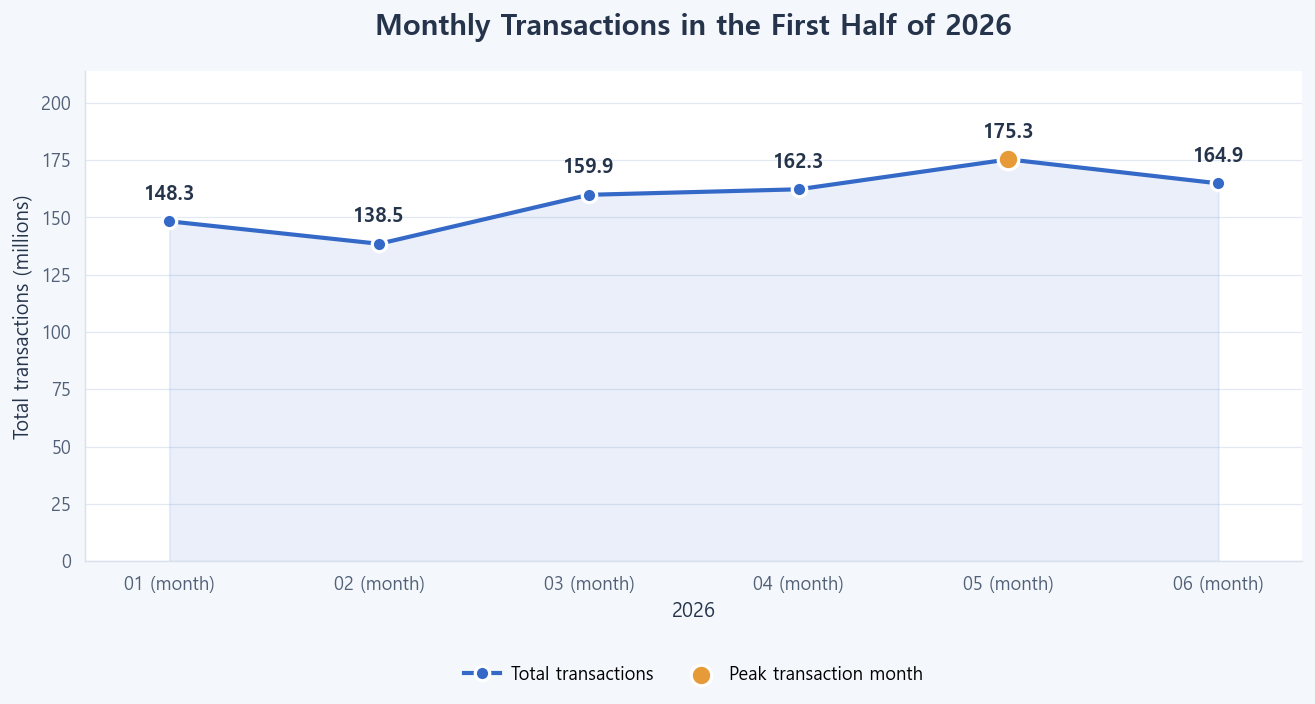

In [ ]:
fig,ax=plt.subplots(figsize=(10,5.3))
month_x=np.arange(len(monthly))
month_y=monthly['cnt'].to_numpy()/1e6
ax.fill_between(month_x,month_y,color=COLORS['blue'],alpha=.10)
ax.plot(month_x,month_y,color=COLORS['blue'],marker='o',markersize=8,
        markeredgecolor='white',markeredgewidth=1.8,label='Total transactions',zorder=3)
peak=int(np.argmax(month_y))
ax.scatter(month_x[peak],month_y[peak],s=130,color=COLORS['orange'],
           edgecolors='white',linewidths=1.8,label='Peak transaction month',zorder=4)
for pos,value in zip(month_x,month_y):
    ax.annotate(f'{value:,.1f}',(pos,value),xytext=(0,12),textcoords='offset points',
                ha='center',fontsize=11,fontweight='bold',color=COLORS['ink'])
ax.set_xticks(month_x,[f'{str(m)[4:]} (month)' for m in monthly['STRD_YYMM']])
ax.set_ylim(0,month_y.max()*1.22)
style_axes(ax,'Monthly Transactions in the First Half of 2026','2026','Total transactions (millions)',grid='y')
legend_below(ax)
plt.show()


## 2. Domestic vs foreign spending structure and TVD

In [6]:
personal = eda[eda['GENDER_CD'].isin(['1','2','3'])].copy()
personal['nat'] = np.where(personal['GENDER_CD'].eq('3'), 'foreign', 'domestic')

personal_totals = personal.groupby('GENDER_CD')[['amt','cnt']].sum()
foreign_amt_share = personal_totals.loc['3','amt']/personal_totals['amt'].sum()
foreign_cnt_share = personal_totals.loc['3','cnt']/personal_totals['cnt'].sum()
print(f'Foreign spending share of personal consumption: {foreign_amt_share:.2%}')
print(f'Foreign transaction share of personal consumption: {foreign_cnt_share:.2%}')
personal_totals

Foreign spending share of personal consumption: 7.90%
Foreign transaction share of personal consumption: 8.54%
Out[6]: 
                     amt        cnt
GENDER_CD                          
1          8805626620000  484721801
2          6084966970000  323656270
3          1278089570000   75509726


### TVD definition
For each region $r$, construct the domestic spending composition $p_{D,rk}$ and foreign spending composition $p_{F,rk}$ across 11 industries, then:

$$TVD_r = \frac{1}{2}\sum_k |p_{D,rk}-p_{F,rk}|$$

- Close to 0: Similar domestic and foreign industry compositions
- Close to 1: Very different spending structures
- Why divide by 1/2: The maximum L1 distance between two probability distributions is 2


In [7]:
rni = personal.groupby(['region','nat','TP_BUZ_NM_CLEAN'])['amt'].sum().reset_index()
rni['share'] = rni.groupby(['region','nat'])['amt'].transform(lambda s: s/s.sum())
p = rni.pivot_table(index=['region','TP_BUZ_NM_CLEAN'], columns='nat', values='share', fill_value=0).reset_index()
p['abs_gap'] = (p['foreign'] - p['domestic']).abs()
tvd_amt = p.groupby('region')['abs_gap'].sum()/2

tvd_amt.describe()

Out[7]: 
count   255.000000
mean      0.185764
std       0.081587
min       0.039409
25%       0.123497
50%       0.169768
75%       0.237801
max       0.453789
Name: abs_gap, dtype: float64


In [8]:
# Count-based TVD: robustness
rni_cnt = personal.groupby(['region','nat','TP_BUZ_NM_CLEAN'])['cnt'].sum().reset_index()
rni_cnt['share'] = rni_cnt.groupby(['region','nat'])['cnt'].transform(lambda s:s/s.sum())
pc = rni_cnt.pivot_table(index=['region','TP_BUZ_NM_CLEAN'], columns='nat', values='share', fill_value=0).reset_index()
pc['abs_gap'] = (pc['foreign'] - pc['domestic']).abs()
tvd_cnt = pc.groupby('region')['abs_gap'].sum()/2

print('AMT-TVD vs CNT-TVD Spearman:', spearmanr(tvd_amt, tvd_cnt).statistic)

AMT-TVD vs CNT-TVD Spearman: 0.9094328971746178


## 3. Structure = Scale × TVD

Scale is **the region's share of all transactions nationwide**. Only foreign transactions are not used because this axis is intended to represent the activity scale of the commercial area itself. With no absolute economic benchmark, the median across 255 regions is used as a relative threshold.

In [9]:
region_cnt = eda.groupby('region')['cnt'].sum()
cnt_share = region_cnt/region_cnt.sum()
scale_thr = cnt_share.median()
tvd_thr = tvd_amt.median()
print(f'Scale median threshold = {scale_thr:.9f}')
print(f'TVD median threshold   = {tvd_thr:.9f}')

structure = pd.Series(index=tvd_amt.index, dtype=object)
structure[(cnt_share>=scale_thr)&(tvd_amt>=tvd_thr)] = 'Large · High divergence'
structure[(cnt_share>=scale_thr)&(tvd_amt<tvd_thr)] = 'Large · Low divergence'
structure[(cnt_share<scale_thr)&(tvd_amt>=tvd_thr)] = 'Small · High divergence'
structure[(cnt_share<scale_thr)&(tvd_amt<tvd_thr)] = 'Small · Low divergence'
structure.value_counts()

Scale median threshold = 0.003508129
TVD median threshold   = 0.169768457
Out[9]: 
Large · Low divergence    79
Small · High divergence    79
Large · High divergence    49
Small · Low divergence    48
Name: count, dtype: int64


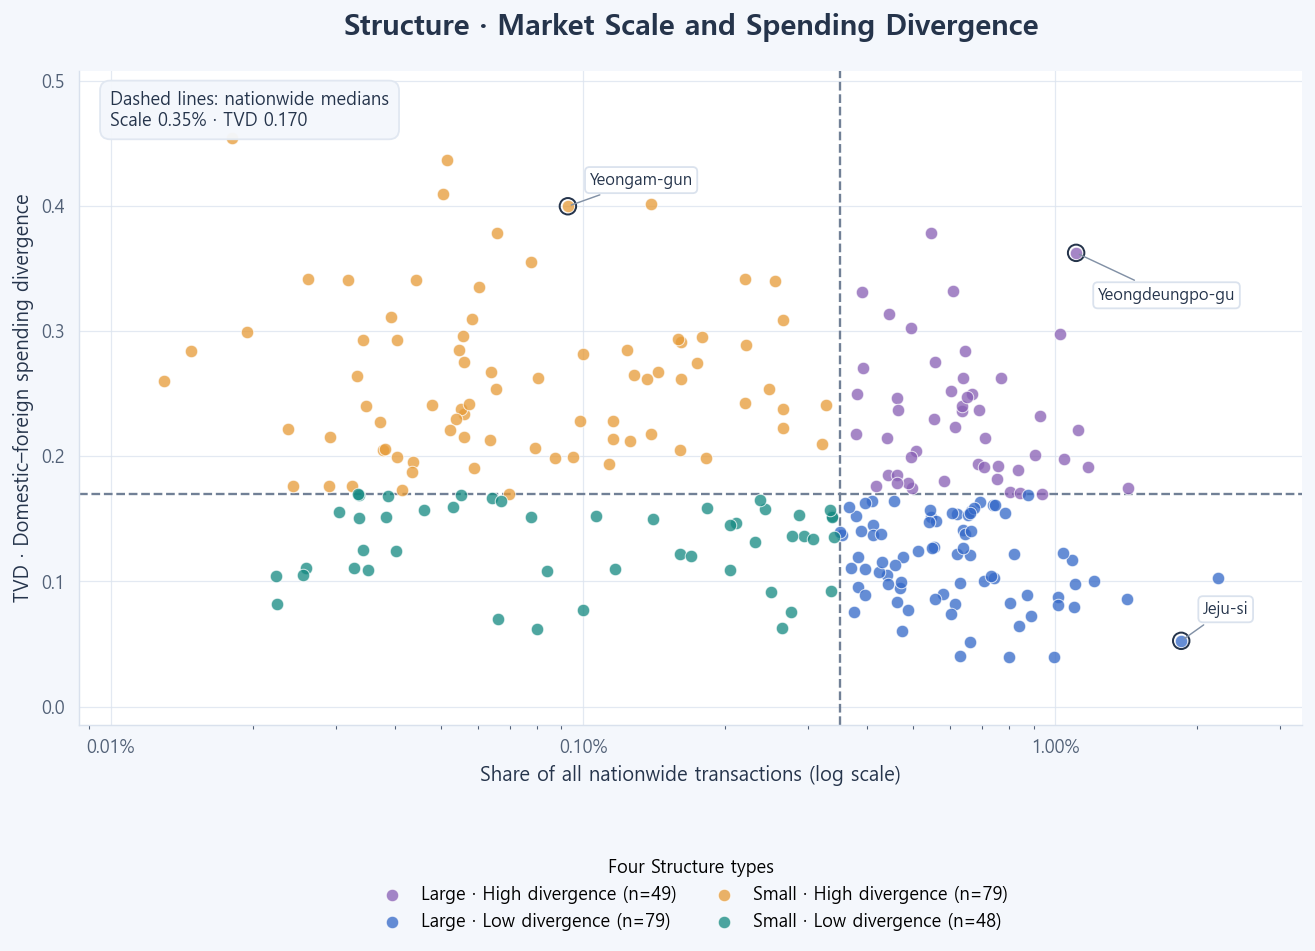

In [ ]:
fig,ax=plt.subplots(figsize=(10,7.2))
category_scatter(ax,cnt_share,tvd_amt,structure,STRUCTURE_COLORS)
ax.set_xscale('log')
ax.axvline(scale_thr,ls='--',color=COLORS['muted'],lw=1.3,zorder=2)
ax.axhline(tvd_thr,ls='--',color=COLORS['muted'],lw=1.3,zorder=2)
ax.xaxis.set_major_formatter(PercentFormatter(xmax=1,decimals=2))
style_axes(ax,'Structure · Market Scale and Spending Divergence',
           'Share of all nationwide transactions (log scale)','TVD · Domestic–foreign spending divergence')
for r,offset in zip(['\uc81c\uc8fc\ud2b9\ubcc4\uc790\uce58\ub3c4 \uc81c\uc8fc\uc2dc','\uc804\ub77c\ub0a8\ub3c4 \uc601\uc554\uad70','\uc11c\uc6b8\ud2b9\ubcc4\uc2dc \uc601\ub4f1\ud3ec\uad6c'],
                    [(12,15),(12,12),(12,-26)]):
    label_region(ax,r,cnt_share.loc[r],tvd_amt.loc[r],offset)
note(ax,f'Dashed lines: nationwide medians\nScale {scale_thr:.2%} · TVD {tvd_thr:.3f}')
legend_below(ax,title='Four Structure types')
plt.show()


## 4. Structure robustness: Does it hold when the period is split in half?

In [11]:
def period_structure(months):
    x = eda[eda['STRD_YYMM'].isin(months)].copy()
    xp = x[x['GENDER_CD'].isin(['1','2','3'])].copy()
    xp['nat'] = np.where(xp['GENDER_CD'].eq('3'),'foreign','domestic')
    z = xp.groupby(['region','nat','TP_BUZ_NM_CLEAN'])['amt'].sum().reset_index()
    z['share'] = z.groupby(['region','nat'])['amt'].transform(lambda s:s/s.sum())
    q = z.pivot_table(index=['region','TP_BUZ_NM_CLEAN'], columns='nat', values='share', fill_value=0).reset_index()
    tv = q.assign(abs_gap=(q['foreign']-q['domestic']).abs()).groupby('region')['abs_gap'].sum()/2
    rc = x.groupby('region')['cnt'].sum(); cs = rc/rc.sum()
    st = pd.Series(index=tv.index, dtype=object)
    st[(cs>=scale_thr)&(tv>=tvd_thr)]='Large · High divergence'
    st[(cs>=scale_thr)&(tv<tvd_thr)]='Large · Low divergence'
    st[(cs<scale_thr)&(tv>=tvd_thr)]='Small · High divergence'
    st[(cs<scale_thr)&(tv<tvd_thr)]='Small · Low divergence'
    fcnt = xp[xp['nat'].eq('foreign')].groupby('region')['cnt'].sum()
    return tv, cs, st, fcnt

T1, S1, ST1, FC1 = period_structure([202601,202602,202603])
T2, S2, ST2, FC2 = period_structure([202604,202605,202606])
print('TVD H1-H2 Pearson:', pearsonr(T1,T2).statistic)
print('TVD H1-H2 Spearman:', spearmanr(T1,T2).statistic)
print('Structure agreement rate:', (ST1==ST2).mean())
print('Cohen kappa:', cohen_kappa_score(ST1,ST2))

TVD H1-H2 Pearson: 0.9476181314006682
TVD H1-H2 Spearman: 0.967245397174618
Structure agreement rate: 0.9215686274509803
Cohen kappa: 0.8932496075353218


In [12]:
rows=[]
for cutoff in [0,5000,10000,50000]:
    mask=(FC1>=cutoff)&(FC2>=cutoff)
    idx=mask[mask].index
    rows.append({
        'Minimum foreign CNT in each half':cutoff,
        'Number of regions':len(idx),
        'TVD Pearson':pearsonr(T1.loc[idx],T2.loc[idx]).statistic,
        'Structure agreement rate':(ST1.loc[idx]==ST2.loc[idx]).mean()
    })
pd.DataFrame(rows)

Out[12]: 
   Minimum foreign CNT in each half  Number of regions  TVD Pearson  Structure agreement rate
0                0   255     0.947618       0.921569
1             5000   249     0.981754       0.927711
2            10000   228     0.985247       0.934211
3            50000   166     0.993153       0.957831


**Interpretation:** TVD and Structure show high reproducibility across periods even across all 255 regions, and are more stable in regions with sufficient foreign transaction volume. Structure is therefore used as a relatively stable 'commercial area profile', while recent changes are separated into Momentum.

## 5. Momentum: Recent changes in CNT × ATV

Because $AMT=CNT\times ATV$, spending changes can be decomposed into changes in transaction count and average transaction value. The baseline windows are H1 (months 1–3) vs H2 (months 4–6), and **excess change** is calculated by subtracting the nationwide change over the same period from the regional change.

$$M^{CNT}_r=\Delta\ln(CNT_r)-\Delta\ln(CNT_{national})$$
$$M^{ATV}_r=\Delta\ln(ATV_r)-\Delta\ln(ATV_{national})$$

All transactions, including corporations, are used here to capture the recent direction of the entire commercial area.

In [13]:
region_month = eda.groupby(['region','STRD_YYMM']).agg(amt=('amt','sum'),cnt=('cnt','sum')).reset_index()

def block_momentum(m1,m2):
    a=region_month[region_month['STRD_YYMM'].isin(m1)].groupby('region')[['amt','cnt']].sum()
    b=region_month[region_month['STRD_YYMM'].isin(m2)].groupby('region')[['amt','cnt']].sum()
    a['atv']=a['amt']/a['cnt']; b['atv']=b['amt']/b['cnt']
    na=region_month[region_month['STRD_YYMM'].isin(m1)][['amt','cnt']].sum()
    nb=region_month[region_month['STRD_YYMM'].isin(m2)][['amt','cnt']].sum()
    out=pd.DataFrame(index=a.index)
    out['CNT']=(np.log(b['cnt']/a['cnt'])-np.log(nb['cnt']/na['cnt']))*100
    out['ATV']=(np.log(b['atv']/a['atv'])-np.log((nb['amt']/nb['cnt'])/(na['amt']/na['cnt'])))*100
    out['AMT']=out['CNT']+out['ATV']
    return out

M3=block_momentum([202601,202602,202603],[202604,202605,202606])
M2=block_momentum([202601,202602],[202605,202606])
print('CNT 3M-2M Pearson:', pearsonr(M3['CNT'],M2['CNT']).statistic)
print('ATV 3M-2M Pearson:', pearsonr(M3['ATV'],M2['ATV']).statistic)
print('Both CNT/ATV directions maintained:', ((np.sign(M3['CNT'])==np.sign(M2['CNT'])) & (np.sign(M3['ATV'])==np.sign(M2['ATV']))).mean())

CNT 3M-2M Pearson: 0.9827255076054494
ATV 3M-2M Pearson: 0.9795359288978002
Both CNT/ATV directions maintained: 0.8823529411764706


## 6. Confidence: Does Momentum remain sufficiently consistent in direction across time windows?

The robust scale of the difference between the 3-month and 2-month values, $D=M_{3M}-M_{2M}$, is calculated as $1.4826\times MAD(D)$.

Each axis (CNT, ATV) is considered **Stable** if both conditions are met.
1. The 3-month and 2-month signals have the same direction
2. Even the smaller absolute signal across the two windows exceeds the robust scale

Thus, this checks not only whether the signs agree, but also **whether the signals are borderline near 0**.
- Both CNT·ATV Stable → High
- Only one axis Stable → Medium
- Neither axis Stable → Low


In [14]:
Dcnt=M3['CNT']-M2['CNT']; Datv=M3['ATV']-M2['ATV']
S_cnt=1.4826*np.median(np.abs(Dcnt-np.median(Dcnt)))
S_atv=1.4826*np.median(np.abs(Datv-np.median(Datv)))
stable_cnt=(np.sign(M3['CNT'])==np.sign(M2['CNT'])) & (np.minimum(np.abs(M3['CNT']),np.abs(M2['CNT']))>S_cnt)
stable_atv=(np.sign(M3['ATV'])==np.sign(M2['ATV'])) & (np.minimum(np.abs(M3['ATV']),np.abs(M2['ATV']))>S_atv)
confidence=pd.Series(np.where(stable_cnt&stable_atv,'High',np.where(stable_cnt|stable_atv,'Medium','Low')),index=M3.index)
print('robust scale CNT:',S_cnt)
print('robust scale ATV:',S_atv)
confidence.value_counts()

robust scale CNT: 2.214311511000665
robust scale ATV: 0.7727485730252659
Out[14]: 
High      119
Medium    110
Low        26
Name: count, dtype: int64


## 7. Integration of external data for 255 regions

In [15]:
moj=pd.read_csv(MOJ_PATH)
pop=pd.read_csv(POP_PATH)
print('MOJ rows:',len(moj),' / population rows:',len(pop))

foreign = personal[personal['nat'].eq('foreign')]
BCf = foreign.groupby('region').agg(BC_foreign_amt_total=('amt','sum'),BC_foreign_cnt_total=('cnt','sum'))
rg = personal.groupby(['region','nat'])['amt'].sum().unstack(fill_value=0)
foreign_share = rg['foreign']/(rg['foreign']+rg['domestic'])

core=pd.DataFrame({
    'region':tvd_amt.index,
    'cnt_share':cnt_share,
    'tvd_amt':tvd_amt,
    'structure':structure,
    'foreign_amt_share_personal':foreign_share,
}).reset_index(drop=True)
core=core.merge(BCf.reset_index(),on='region').merge(pop[['region','resident_population_202606']],on='region').merge(moj[['region','MOJ_registered_foreigners_202606']],on='region')
core['registered_foreign_share']=core['MOJ_registered_foreigners_202606']/(core['resident_population_202606']+core['MOJ_registered_foreigners_202606'])
print('Final join:',core.shape)
print('Missing values:',core.isna().sum().sum())
core.head()

MOJ rows: 255  / population rows: 255
Final join: (255, 10)
Missing values: 0
Out[15]: 
        region  cnt_share  tvd_amt structure  foreign_amt_share_personal  \
0  Gangwon-do Gangneung-si   0.003786 0.152142   Large · Low divergence                    0.052001   
1  Gangwon-do Goseong-gun   0.000443 0.341093   Small · High divergence                    0.081873   
2  Gangwon-do Donghae-si   0.001406 0.150027   Small · Low divergence                    0.048816   
3  Gangwon-do Samcheok-si   0.000642 0.166922   Small · Low divergence                    0.046824   
4  Gangwon-do Sokcho-si   0.002429 0.158036   Small · Low divergence                    0.052359   

   BC_foreign_amt_total  BC_foreign_cnt_total  resident_population_202606  \
0            4200020000                224659                      205666   
1             695930000                 67590                       27204   
2            1436770000                 66023                       85589   
3             6659

## 8. External validation A: Does BC foreign spending scale converge with the actual distribution of registered foreigners?

In [16]:
x=np.log1p(core['MOJ_registered_foreigners_202606'])
y_amt=np.log1p(core['BC_foreign_amt_total'])
y_cnt=np.log1p(core['BC_foreign_cnt_total'])
print('AMT Pearson / Spearman:', pearsonr(y_amt,x).statistic, spearmanr(y_amt,x).statistic)
print('CNT Pearson / Spearman:', pearsonr(y_cnt,x).statistic, spearmanr(y_cnt,x).statistic)
model=sm.OLS(y_amt,sm.add_constant(x)).fit()
print('AMT regression R²:',model.rsquared)

AMT Pearson / Spearman: 0.8751688870876112 0.8845708830971676
CNT Pearson / Spearman: 0.8821514104896784 0.8965092869833746
AMT regression R²: 0.7659205809261682


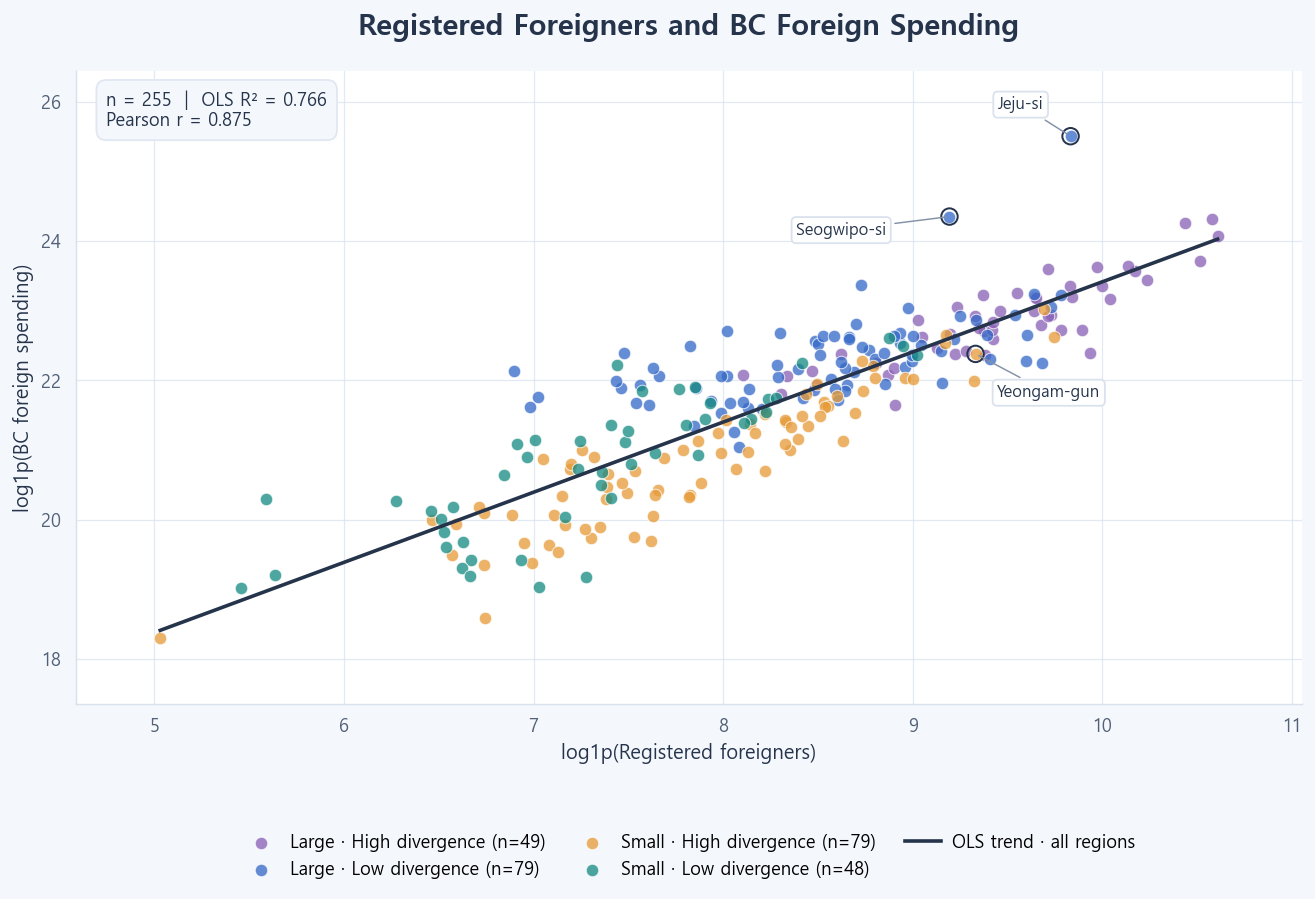

In [ ]:
fig,ax=plt.subplots(figsize=(10,6.8))
category_scatter(ax,x,y_amt,core['structure'],STRUCTURE_COLORS)
xx=np.linspace(x.min(),x.max(),200)
ax.plot(xx,model.params.iloc[0]+model.params.iloc[1]*xx,color=COLORS['ink'],
        lw=2,label='OLS trend · all regions',zorder=4)
for r,offset in zip(['\uc81c\uc8fc\ud2b9\ubcc4\uc790\uce58\ub3c4 \uc81c\uc8fc\uc2dc','\uc81c\uc8fc\ud2b9\ubcc4\uc790\uce58\ub3c4 \uc11c\uadc0\ud3ec\uc2dc','\uc804\ub77c\ub0a8\ub3c4 \uc601\uc554\uad70'],
                    [(-15,15),(-35,-10),(12,-24)]):
    row=core[core['region']==r].iloc[0]
    label_region(ax,r,np.log1p(row['MOJ_registered_foreigners_202606']),
                 np.log1p(row['BC_foreign_amt_total']),offset)
style_axes(ax,'Registered Foreigners and BC Foreign Spending','log1p(Registered foreigners)','log1p(BC foreign spending)')
note(ax,f'n = {len(core):,}  |  OLS R² = {model.rsquared:.3f}\nPearson r = {pearsonr(x,y_amt).statistic:.3f}')
legend_below(ax,ncol=3)
plt.show()


## 9. External validation B: TVD and registered foreigner share — All 255 regions

In [18]:
pr=pearsonr(core['tvd_amt'],core['registered_foreign_share'])
sr=spearmanr(core['tvd_amt'],core['registered_foreign_share'])
print(f'Pearson r={pr.statistic:.3f}, p={pr.pvalue:.3e}')
print(f'Spearman rho={sr.statistic:.3f}, p={sr.pvalue:.3e}')

Pearson r=0.659, p=4.270e-33
Spearman rho=0.714, p=5.330e-41


In [19]:
# bootstrap 95% CI
rng=np.random.default_rng(42)
a=core[['tvd_amt','registered_foreign_share']].to_numpy()
bp=[]; bs=[]
for _ in range(5000):
    ii=rng.integers(0,len(a),len(a))
    xx,yy=a[ii,0],a[ii,1]
    bp.append(np.corrcoef(xx,yy)[0,1])
    bs.append(spearmanr(xx,yy).statistic)
print('Pearson 95% CI:',np.quantile(bp,[.025,.975]))
print('Spearman 95% CI:',np.quantile(bs,[.025,.975]))

Pearson 95% CI: [0.59418101 0.72201986]
Spearman 95% CI: [0.64420988 0.77214778]


A higher Spearman than Pearson means that **the rank-based, monotonic tendency for foreigner share to rise with TVD is stronger than the linear relationship**. Given extreme values/nonlinearity in foreigner share, it is natural to treat Spearman as the primary measure and Pearson as a supplementary measure.

In [20]:
q33,q67=core['tvd_amt'].quantile([1/3,2/3])
core['tvd_tertile']=pd.cut(core['tvd_amt'],[-np.inf,q33,q67,np.inf],labels=['Low','Mid','High'],include_lowest=True)
tert=core.groupby('tvd_tertile',observed=True)['registered_foreign_share'].agg(['count','median','mean'])
print('TVD 33.3% / 66.7% thresholds:',q33,q67)
tert.assign(median_pct=tert['median']*100,mean_pct=tert['mean']*100)

TVD 33.3% / 66.7% thresholds: 0.14628712438215796 0.21443130371565225
Out[20]: 
             count   median     mean  median_pct  mean_pct
tvd_tertile                                               
Low             85 0.015805 0.019471    1.580470  1.947132
Mid             85 0.028253 0.031611    2.825302  3.161086
High            85 0.048110 0.055228    4.810992  5.522772


In [21]:
low=core[core['tvd_amt']<tvd_thr]['registered_foreign_share']
high=core[core['tvd_amt']>=tvd_thr]['registered_foreign_share']
u=mannwhitneyu(low,high,alternative='two-sided')
print(f'Low-divergence median: {low.median():.2%}')
print(f'High-divergence median: {high.median():.2%}')
print(f'Median ratio: {high.median()/low.median():.2f}x')
print(f'Mann–Whitney p={u.pvalue:.3e}')

Low-divergence median: 1.97%
High-divergence median: 4.28%
Median ratio: 2.17x
Mann–Whitney p=4.434e-24


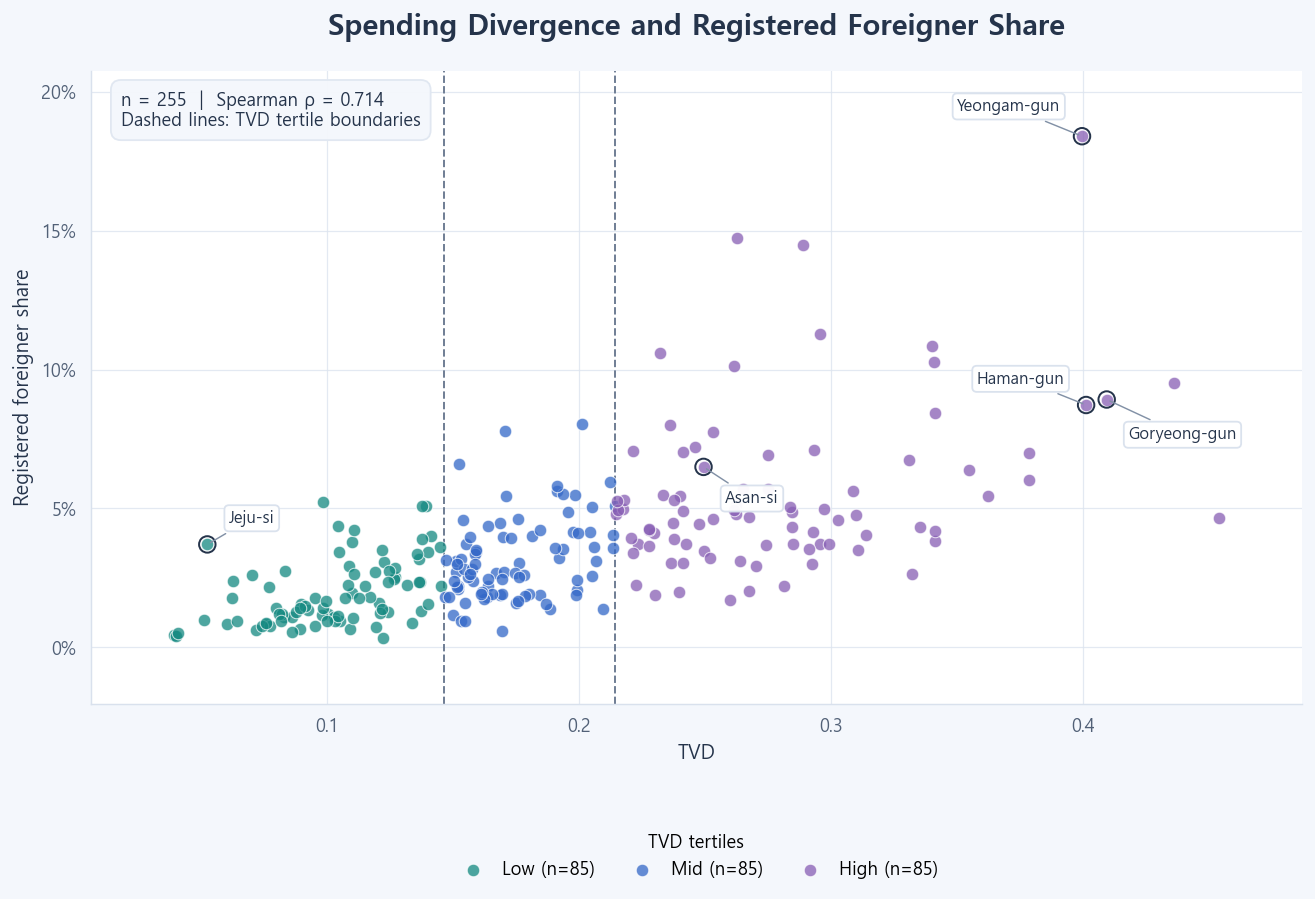

In [ ]:
fig,ax=plt.subplots(figsize=(10,6.8))
tertile_colors={'Low':COLORS['teal'],'Mid':COLORS['blue'],'High':COLORS['purple']}
category_scatter(ax,core['tvd_amt'],core['registered_foreign_share']*100,
                 core['tvd_tertile'],tertile_colors)
tvd_cuts=core['tvd_amt'].quantile([1/3,2/3]).to_numpy()
for cut in tvd_cuts:
    ax.axvline(cut,color=COLORS['muted'],ls='--',lw=1.1,zorder=2)
for r,offset in zip(['\uc81c\uc8fc\ud2b9\ubcc4\uc790\uce58\ub3c4 \uc81c\uc8fc\uc2dc','\uc804\ub77c\ub0a8\ub3c4 \uc601\uc554\uad70','\uacbd\uc0c1\ubd81\ub3c4 \uace0\ub839\uad70',
                     '\uacbd\uc0c1\ub0a8\ub3c4 \ud568\uc548\uad70','\ucda9\uccad\ub0a8\ub3c4 \uc544\uc0b0\uc2dc'],
                    [(12,12),(-12,14),(12,-22),(-12,12),(12,-20)]):
    row=core[core['region']==r].iloc[0]
    label_region(ax,r,row['tvd_amt'],row['registered_foreign_share']*100,offset)
style_axes(ax,'Spending Divergence and Registered Foreigner Share','TVD','Registered foreigner share')
ax.yaxis.set_major_formatter(PercentFormatter(xmax=100,decimals=0))
note(ax,f'n = {len(core):,}  |  Spearman ρ = {sr.statistic:.3f}\nDashed lines: TVD tertile boundaries')
legend_below(ax,ncol=3,title='TVD tertiles')
plt.show()


## 10. Representative cases: Even key foreign spending regions differ in structure

In [23]:
case_regions=['\uc81c\uc8fc\ud2b9\ubcc4\uc790\uce58\ub3c4 \uc81c\uc8fc\uc2dc','\uc81c\uc8fc\ud2b9\ubcc4\uc790\uce58\ub3c4 \uc11c\uadc0\ud3ec\uc2dc','\uc804\ub77c\ub0a8\ub3c4 \uc601\uc554\uad70','\uacbd\uc0c1\ubd81\ub3c4 \uace0\ub839\uad70','\uacbd\uc0c1\ub0a8\ub3c4 \ud568\uc548\uad70','\ucda9\uccad\ub0a8\ub3c4 \uc544\uc0b0\uc2dc']
case=core[core['region'].isin(case_regions)][['region','structure','foreign_amt_share_personal','tvd_amt','resident_population_202606','MOJ_registered_foreigners_202606','registered_foreign_share']].copy()
case['foreign_amt_share_personal']*=100
case['registered_foreign_share']*=100
case.sort_values('tvd_amt')

Out[23]: 
           region structure  foreign_amt_share_personal  tvd_amt  \
224   Jeju-do Jeju-si   Large · Low divergence                   36.380760 0.052582   
223  Jeju-do Seogwipo-si   Large · Low divergence                   29.693743 0.098454   
234      Chungcheongnam-do Asan-si   Large · High divergence                   16.602717 0.249442   
200      Jeollanam-do Yeongam-gun   Small · High divergence                   32.179733 0.399595   
84       Gyeongsangnam-do Haman-gun   Small · High divergence                   12.286506 0.401225   
89       Gyeongsangbuk-do Goryeong-gun   Small · High divergence                   18.746079 0.409393   

     resident_population_202606  MOJ_registered_foreigners_202606  \
224                      484123                             18638   
223                      178669                              9838   
234                      363678                             25268   
200                       50076                             

- Jeju-si: Foreign spending share is very high, but TVD is low and registered foreigner share is also much lower than in Yeongam. This is consistent with **the possibility of a mix of visitor/inbound demand**, but the cause is not established without tourist data.
- Yeongam-gun: Foreign spending share is high, and both TVD and registered foreigner share are also very high. This case has a relatively strong **association with the everyday needs of resident foreigners**.
- Spending structures should therefore be distinguished rather than grouped under a single label of `places where foreigners spend heavily`.

## 11. Residual analysis: Foreign card spending unexplained by registered foreigner counts

In [24]:
resid=(model.resid-model.resid.mean())/model.resid.std(ddof=1)
core['std_residual']=resid.values
print('Largest positive (+) residuals')
display(core.nlargest(8,'std_residual')[['region','MOJ_registered_foreigners_202606','foreign_amt_share_personal','tvd_amt','std_residual']])
print('Most negative (-) residuals')
display(core.nsmallest(5,'std_residual')[['region','MOJ_registered_foreigners_202606','foreign_amt_share_personal','tvd_amt','std_residual']])

Largest positive (+) residuals
Most negative (-) residuals


,region,MOJ_registered_foreigners_202606,foreign_amt_share_personal,tvd_amt,std_residual
224,Jeju-do Jeju-si,18638,0.363808,0.052582,3.910547
123,Daegu Jung-gu,986,0.047249,0.154846,3.189047
223,Jeju-do Seogwipo-si,9838,0.296937,0.098454,3.026684
122,Daegu Suseong-gu,1764,0.035770,0.039409,2.626793
250,Chungcheongbuk-do Cheongju-si Sangdang-gu,1703,0.090027,0.075868,2.398829
134,Busan Dongnae-gu,1119,0.022679,0.039988,2.333183
22,Gyeonggi-do Gwacheon-si,266,0.031541,0.122125,2.294422
114,Gwangju Seo-gu,3034,0.058402,0.082872,2.236471


,region,MOJ_registered_foreigners_202606,foreign_amt_share_personal,tvd_amt,std_residual
98,Gyeongsangbuk-do Yeongyang-gun,848,0.059220,0.283688,-2.672140
9,Gangwon-do Inje-gun,1448,0.032884,0.168563,-2.602265
222,Jeonbuk-do Jinan-gun,1128,0.045681,0.104237,-2.400941
11,Gangwon-do Cheorwon-gun,2041,0.038648,0.195700,-2.299528
49,Gyeonggi-do Yeoncheon-gun,1863,0.046741,0.292681,-2.034460


Residuals are not causes themselves. Positive (+) residuals indicate regions with more card spending than their registered foreigner scale would imply, making them candidates for further testing of external demand hypotheses such as tourism, commuting, and shopping inflows. Negative (-) residuals identify candidates for examining possibilities such as spending outside the region, cash/other-card payments, and merchant coverage.

## 12. Korea Tourism Organization 2026H1 visitor data and External Context

Daily data for **2026-01-01~2026-06-30** from the Korea Tourism Organization's `Regional Visitor Counts` OpenAPI is integrated to match the BC card data period exactly.

- `touDivCd=1`: Local residents (a)
- `touDivCd=2`: Out-of-town domestic visitors (b)
- `touDivCd=3`: Foreigners (c)

In this analysis, foreign visit share is defined as **the share of foreigners among external visitors**.

\[
ForeignVisitShare_r=\frac{Foreign_r}{OutOfTown_r+Foreign_r}
\]

Local residents are not included in the denominator as in the initial summary file. Mobile-network-based 'visitors' do not directly identify the purpose of a visit, so the final label is **visitor-dominant** rather than 'tourism-oriented'.

In [25]:
# KTO 2026H1 raw load & correct foreign visit share
kto = pd.read_csv(KTO_RAW_PATH, dtype={'signguCode':str,'touDivCd':str,'baseYmd':str})
kto['touDivCd'] = kto['touDivCd'].str.replace('.0','',regex=False)

sido_map = {
    '11':'\uc11c\uc6b8\ud2b9\ubcc4\uc2dc','26':'\ubd80\uc0b0\uad11\uc5ed\uc2dc','27':'\ub300\uad6c\uad11\uc5ed\uc2dc','28':'\uc778\ucc9c\uad11\uc5ed\uc2dc',
    '29':'\uad11\uc8fc\uad11\uc5ed\uc2dc','30':'\ub300\uc804\uad11\uc5ed\uc2dc','31':'\uc6b8\uc0b0\uad11\uc5ed\uc2dc','36':'\uc138\uc885\ud2b9\ubcc4\uc790\uce58\uc2dc',
    '41':'\uacbd\uae30\ub3c4','43':'\ucda9\uccad\ubd81\ub3c4','44':'\ucda9\uccad\ub0a8\ub3c4','46':'\uc804\ub77c\ub0a8\ub3c4','47':'\uacbd\uc0c1\ubd81\ub3c4',
    '48':'\uacbd\uc0c1\ub0a8\ub3c4','50':'\uc81c\uc8fc\ud2b9\ubcc4\uc790\uce58\ub3c4','51':'\uac15\uc6d0\ud2b9\ubcc4\uc790\uce58\ub3c4','52':'\uc804\ubd81\ud2b9\ubcc4\uc790\uce58\ub3c4'
}
kto['SIDO_NM'] = kto['signguCode'].str[:2].map(sido_map)

kagg = (kto[kto['touDivCd'].isin(['2','3'])]
        .groupby(['SIDO_NM','signguCode','signguNm','touDivCd'],as_index=False)['touNum'].sum())
kp = (kagg.pivot_table(index=['SIDO_NM','signguCode','signguNm'], columns='touDivCd', values='touNum', fill_value=0)
      .reset_index())
kp.columns.name = None
kp = kp.rename(columns={'signguNm':'CCG_NM','2':'kto_out_of_town_total','3':'kto_foreign_total'})
kp['kto_foreign_visit_share'] = kp['kto_foreign_total']/(kp['kto_foreign_total']+kp['kto_out_of_town_total'])

obs = (kto[kto['touDivCd'].eq('3')]
       .groupby(['SIDO_NM','signguCode','signguNm'])['baseYmd'].nunique()
       .reset_index(name='kto_foreign_observed_days')
       .rename(columns={'signguNm':'CCG_NM'}))
kp = kp.merge(obs,on=['SIDO_NM','signguCode','CCG_NM'],how='left')
print('KTO raw rows:', len(kto))
print('KTO date range:', kto['baseYmd'].min(), '~', kto['baseYmd'].max())
print(kp['kto_foreign_observed_days'].value_counts().sort_index())
kp.head()

KTO raw rows: 145152
KTO date range: 20260101 ~ 20260630
kto_foreign_observed_days
150      4
181    264
Name: count, dtype: int64
Out[25]: 
   SIDO_NM signguCode CCG_NM  kto_out_of_town_total  kto_foreign_total  \
0  Gangwon-do      51110    Chuncheon-si      14,525,024.500000     536,202.330000   
1  Gangwon-do      51130    Wonju-si      17,060,893.500000     180,404.400000   
2  Gangwon-do      51150    Gangneung-si      16,798,516.000000     205,463.510000   
3  Gangwon-do      51170    Donghae-si       6,278,695.500000      74,553.580000   
4  Gangwon-do      51190    Taebaek-si       2,498,100.500000      27,779.290000   

   kto_foreign_visit_share  kto_foreign_observed_days  
0                 0.035602                        181  
1                 0.010464                        181  
2                 0.012083                        181  
3                 0.011735                        181  
4                 0.010998                        181  


### 12.1 Integration with 255 BC regions and the strict sample

KTO and BC regional names are joined using `SIDO_NM + CCG_NM`. All 255 regions match, but the 4 newly established districts of Hwaseong-si have only 150 days of KTO data. The main validation uses **251 regions** with observations for all 181 days, while the 4 regions are retained separately for sensitivity analysis.

In [26]:
external_full = pd.read_csv(EXT_JOINED_PATH)
context = external_full.merge(
    kp[['SIDO_NM','CCG_NM','signguCode','kto_out_of_town_total','kto_foreign_total','kto_foreign_visit_share','kto_foreign_observed_days']],
    on=['SIDO_NM','CCG_NM'], how='left', validate='1:1'
)
print('BC regions:', len(context))
print('KTO matched:', context['kto_foreign_visit_share'].notna().sum())
print(context['kto_foreign_observed_days'].value_counts().sort_index())
strict = context[context['kto_foreign_observed_days'].eq(181)].copy()
print('strict N:', len(strict))

BC regions: 255
KTO matched: 255
kto_foreign_observed_days
150      4
181    251
Name: count, dtype: int64
strict N: 251


### 12.2 ContextGap definition

The comparison concerns **the relative imbalance between resident concentration and visitor concentration**, rather than absolute visitor volume itself.

\[
ContextGap_r=Pctl(ForeignVisitShare_r)-Pctl(RegisteredForeignShare_r)
\]

- High value: Greater foreign visitor presence relative to registered foreigners → Visitor-dominant
- Low value: Greater registered foreigner concentration relative to visits → Resident-dominant
- Intermediate value: Mixed

In [27]:
strict['visitor_pctile'] = strict['kto_foreign_visit_share'].rank(method='average',pct=True)*100
strict['resident_pctile'] = strict['registered_foreign_share'].rank(method='average',pct=True)*100
strict['context_gap'] = strict['visitor_pctile'] - strict['resident_pctile']

# Residuals from expected BC foreign spending explained solely by registered foreigner scale
X = sm.add_constant(np.log1p(strict['MOJ_registered_foreigners_202606']))
y = np.log1p(strict['BC_foreign_amt_total'])
base_spend_model = sm.OLS(y, X).fit()
strict['bc_spend_residual'] = base_spend_model.resid

print('base model R2:', round(base_spend_model.rsquared,4))
print('ContextGap vs BC residual')
print(' Pearson:', pearsonr(strict['context_gap'],strict['bc_spend_residual']))
print(' Spearman:', spearmanr(strict['context_gap'],strict['bc_spend_residual']))
print('ContextGap vs TVD')
print(' Pearson:', pearsonr(strict['context_gap'],strict['tvd_amt']))
print(' Spearman:', spearmanr(strict['context_gap'],strict['tvd_amt']))
print('Raw visit share vs BC residual')
print(' Pearson:', pearsonr(strict['kto_foreign_visit_share'],strict['bc_spend_residual']))

base model R2: 0.7624
ContextGap vs BC residual
 Pearson: PearsonRResult(statistic=np.float64(0.3629522448840826), pvalue=np.float64(3.1265418408793626e-09))
 Spearman: SignificanceResult(statistic=np.float64(0.3691755640106738), pvalue=np.float64(1.5980568481186151e-09))
ContextGap vs TVD
 Pearson: PearsonRResult(statistic=np.float64(-0.37848860140520146), pvalue=np.float64(5.697204657375256e-10))
 Spearman: SignificanceResult(statistic=np.float64(-0.4018003548229578), pvalue=np.float64(3.7204912920413196e-11))
Raw visit share vs BC residual
 Pearson: PearsonRResult(statistic=np.float64(0.01059959573032677), pvalue=np.float64(0.8672947897120437))


### Key interpretation

Even after aligning the period fully to 2026H1, `ContextGap` shows a significant positive (+) relationship with BC foreign spending residuals and a significant negative (-) relationship with TVD. In contrast, the Pearson correlation between foreign visit share itself and BC spending residuals is effectively 0.

Thus, the interpretation is not **'more foreign visits mean higher BC spending'**, but that the relative Context of **'how high foreign visitor concentration is relative to resident foreigner concentration'** is associated with spending patterns.

In [28]:
q33, q67 = strict['context_gap'].quantile([1/3,2/3])
strict['external_context'] = pd.cut(
    strict['context_gap'], [-np.inf,q33,q67,np.inf],
    labels=['Resident-dominant','Mixed','Visitor-dominant'], include_lowest=True
)
summary_context = strict.groupby('external_context', observed=False).agg(
    n=('region','size'),
    visit_share_median=('kto_foreign_visit_share','median'),
    resident_share_median=('registered_foreign_share','median'),
    bc_residual_median=('bc_spend_residual','median'),
    tvd_median=('tvd_amt','median')
)
print('Q33=',q33,'Q67=',q67)
display(summary_context)
print('Kruskal BC residual:', kruskal(*[g['bc_spend_residual'] for _,g in strict.groupby('external_context',observed=False)]))
print('Kruskal TVD:', kruskal(*[g['tvd_amt'] for _,g in strict.groupby('external_context',observed=False)]))

Q33= -15.53784860557769 Q67= 7.436918990703839
Kruskal BC residual: KruskalResult(statistic=np.float64(29.090831684599493), pvalue=np.float64(4.819546365821254e-07))
Kruskal TVD: KruskalResult(statistic=np.float64(33.691659284235584), pvalue=np.float64(4.830022383093407e-08))


,n,visit_share_median,resident_share_median,bc_residual_median,tvd_median
external_context,,,,,
Resident-dominant,84,0.012102,0.042292,-0.219473,0.214995
Mixed,83,0.013358,0.027327,0.040962,0.164034
Visitor-dominant,84,0.025459,0.021126,0.149551,0.144023


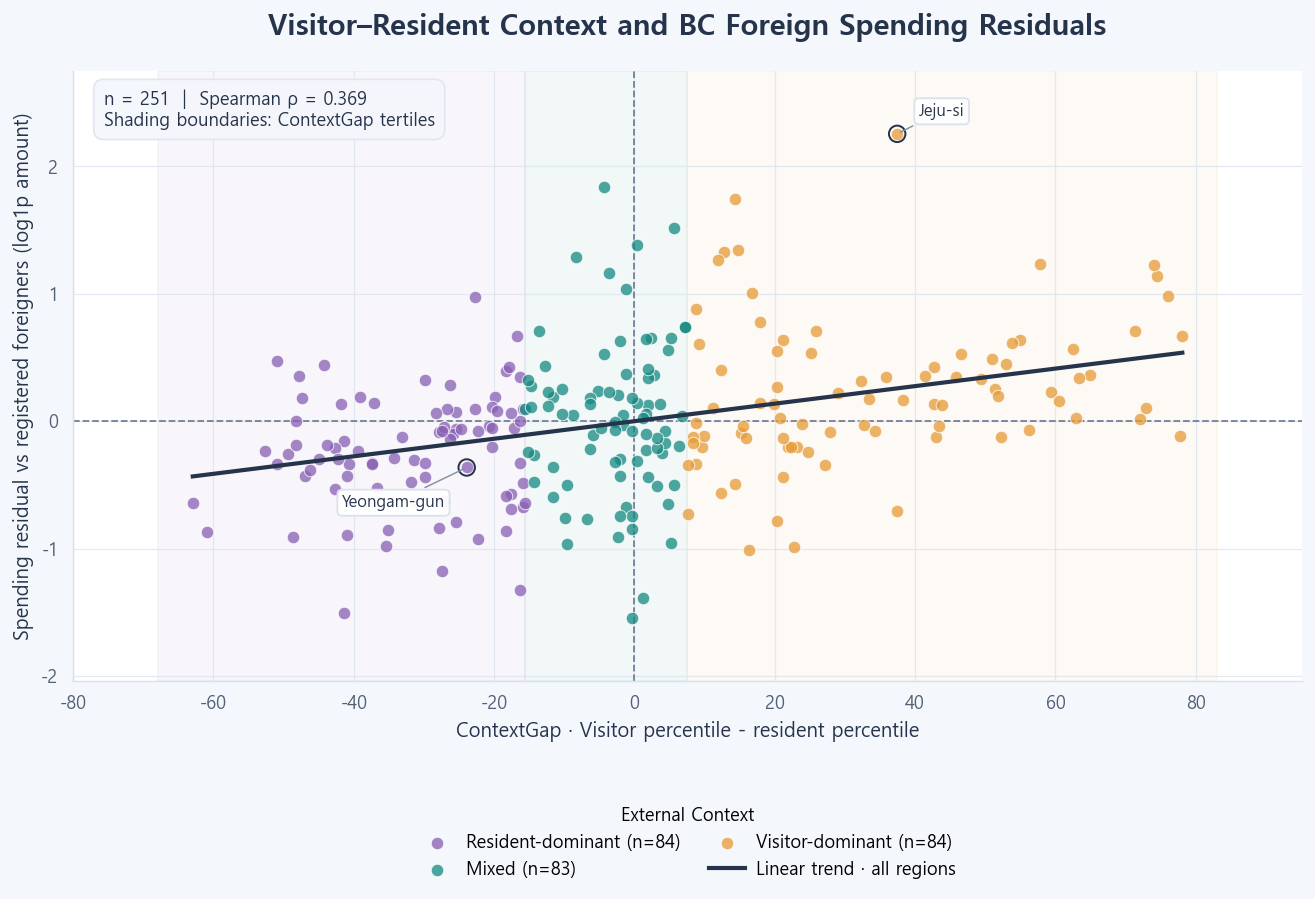

In [ ]:
fig,ax=plt.subplots(figsize=(10,6.8))
context_cuts=strict['context_gap'].quantile([1/3,2/3]).to_numpy()
edges=[strict['context_gap'].min()-5,*context_cuts,strict['context_gap'].max()+5]
for (name,color),left,right in zip(CONTEXT_COLORS.items(),edges[:-1],edges[1:]):
    ax.axvspan(left,right,color=color,alpha=.055,zorder=0)
category_scatter(ax,strict['context_gap'],strict['bc_spend_residual'],
                 strict['external_context'],CONTEXT_COLORS)
coef=np.polyfit(strict['context_gap'],strict['bc_spend_residual'],1)
xx=np.linspace(strict['context_gap'].min(),strict['context_gap'].max(),200)
ax.plot(xx,coef[0]*xx+coef[1],color=COLORS['ink'],label='Linear trend · all regions',zorder=4)
ax.axhline(0,color=COLORS['muted'],lw=1,ls='--',zorder=2)
ax.axvline(0,color=COLORS['muted'],lw=1,ls='--',zorder=2)
style_axes(ax,'Visitor–Resident Context and BC Foreign Spending Residuals',
           'ContextGap · Visitor percentile - resident percentile','Spending residual vs registered foreigners (log1p amount)')
note(ax,f'n = {len(strict):,}  |  Spearman ρ = {spearmanr(strict.context_gap,strict.bc_spend_residual).statistic:.3f}\nShading boundaries: ContextGap tertiles')
for r,offset in zip(['\uc81c\uc8fc\ud2b9\ubcc4\uc790\uce58\ub3c4 \uc81c\uc8fc\uc2dc','\uc804\ub77c\ub0a8\ub3c4 \uc601\uc554\uad70'],[(12,10),(-12,-22)]):
    row=strict[strict['region']==r].iloc[0]
    label_region(ax,r,row['context_gap'],row['bc_spend_residual'],offset)
legend_below(ax,ncol=2,title='External Context')
plt.show()


### 12.3 Representative cases: Jeju vs Yeongam

Even among 'regions where foreign spending is important', external visitor demand and resident demand can differ in nature. Jeju-si is classified as visitor-dominant, while Yeongam-gun is resident-dominant. Gangnam·Haeundae are strongly visitor-dominant, while Geoje is a mixed case with high levels of both foreign visits and foreign residency.

In [30]:
cases = ['\uc81c\uc8fc\ud2b9\ubcc4\uc790\uce58\ub3c4 \uc81c\uc8fc\uc2dc','\uc804\ub77c\ub0a8\ub3c4 \uc601\uc554\uad70','\uc11c\uc6b8\ud2b9\ubcc4\uc2dc \uac15\ub0a8\uad6c','\ubd80\uc0b0\uad11\uc5ed\uc2dc \ud574\uc6b4\ub300\uad6c','\uacbd\uc0c1\ub0a8\ub3c4 \uac70\uc81c\uc2dc']
strict[strict['region'].isin(cases)][[
    'region','kto_foreign_visit_share','visitor_pctile','registered_foreign_share','resident_pctile',
    'context_gap','external_context','tvd_amt','bc_spend_residual'
]].sort_values('context_gap',ascending=False)

Out[30]: 
          region  kto_foreign_visit_share  visitor_pctile  \
144   Busan Haeundae-gu                 0.078586       92.828685   
145    Seoul Gangnam-gu                 0.042790       85.258964   
224  Jeju-do Jeju-si                 0.184557       98.804781   
65      Gyeongsangnam-do Geoje-si                 0.092249       94.820717   
200     Jeollanam-do Yeongam-gun                 0.028351       76.095618   

     registered_foreign_share  resident_pctile  context_gap external_context  \
144                  0.012889        14.741036    78.087649            Visitor-dominant   
145                  0.011025        11.155378    74.103586            Visitor-dominant   
224                  0.037071        61.354582    37.450199            Visitor-dominant   
65                   0.067464        91.633466     3.187251              Mixed   
200                  0.183952       100.000000   -23.904382            Resident-dominant   

     tvd_amt  bc_spend_residual  
144 0.0877

## 13. Generation of the final Action Matrix

In [31]:
action=pd.DataFrame(index=tvd_amt.index)
action['structure']=structure
action['cnt_share']=cnt_share
action['tvd_amt']=tvd_amt
action['foreign_amt_share_personal']=foreign_share
action['momentum_cnt']=M3['CNT']
action['momentum_atv']=M3['ATV']
action['confidence']=confidence

def sig(r):
    c=M3.loc[r,'CNT']; a=M3.loc[r,'ATV']
    if c>0 and a>0:return 'Transactions and ATV both rising'
    if c>0:return 'Transaction expansion'
    if a>0:return 'ATV rising'
    return 'Both weakening'
action['momentum_signal']=[sig(r) for r in action.index]
action.reset_index(names='region').head(10)

Out[31]: 
        region structure  cnt_share  tvd_amt  foreign_amt_share_personal  \
0  Gangwon-do Gangneung-si   Large · Low divergence   0.003786 0.152142                    0.052001   
1  Gangwon-do Goseong-gun   Small · High divergence   0.000443 0.341093                    0.081873   
2  Gangwon-do Donghae-si   Small · Low divergence   0.001406 0.150027                    0.048816   
3  Gangwon-do Samcheok-si   Small · Low divergence   0.000642 0.166922                    0.046824   
4  Gangwon-do Sokcho-si   Small · Low divergence   0.002429 0.158036                    0.052359   
5  Gangwon-do Yanggu-gun   Small · High divergence   0.000243 0.176053                    0.094434   
6  Gangwon-do Yangyang-gun   Small · Low divergence   0.000551 0.168776                    0.047848   
7  Gangwon-do Yeongwol-gun   Small · High divergence   0.000347 0.239894                    0.065388   
8  Gangwon-do Wonju-si   Large · Low divergence   0.005783 0.089870                    0.065569 

### Distinct roles of the indicators

- **Structure** → What kind of commercial area is it? (`Scale × TVD`)
- **Momentum** → In which direction has it been moving recently? (`CNT × ATV`)
- **Confidence** → How strongly can the recent signal be trusted?
- **External Context** → Which external context, such as residency, visits, or tourism, is it consistent with?
- **Action** → What should each stakeholder do?


## 14. Proposal for the LLM Action Layer

The LLM does not replace numerical calculations or regional type classification. It receives a structured diagnostic packet first finalized by the analytics engine.

`Raw Data → Analytics Engine → Labels → Rule Layer → Evidence Layer → LLM → Stakeholder Action`

Recommended stakeholders:
1. BC Card — Targeted promotions, merchant prospecting, and commercialization of commercial area segments
2. Small business owners/entrepreneurs — Undersupplied industries, customer composition, and location/product strategy
3. Local governments — Commercial area support and everyday service strategies based on resident-dominant·mixed·visitor-dominant contexts (Section 12, External Context)

The key is to store `Source / Fact / Applicability Conditions / Supported Action / Exclusion Conditions / Evidence Grade / Reference Date` in the Evidence Layer and constrain the LLM from freely inventing strategies absent from the KB.

In [32]:
# Example: Jeju diagnostic packet passed to the LLM
r='\uc81c\uc8fc\ud2b9\ubcc4\uc790\uce58\ub3c4 \uc81c\uc8fc\uc2dc'
row=core[core['region']==r].iloc[0]
crow=strict[strict['region']==r].iloc[0]   # External Context classified in Section 12
packet={
    'region':r,
    'structure':structure.loc[r],
    'tvd':round(float(tvd_amt.loc[r]),3),
    'scale_share':round(float(cnt_share.loc[r]),6),
    'foreign_amt_share':round(float(foreign_share.loc[r]),3),
    'momentum_cnt':round(float(M3.loc[r,'CNT']),2),
    'momentum_atv':round(float(M3.loc[r,'ATV']),2),
    'confidence':confidence.loc[r],
    'registered_foreign_share':round(float(row['registered_foreign_share']),4),
    # Section 12 External Context classification (KTO 2026H1 + registered foreigner share, strict sample)
    'foreign_visit_share':round(float(crow['kto_foreign_visit_share']),4),
    'visitor_pctile':round(float(crow['visitor_pctile']),1),
    'resident_pctile':round(float(crow['resident_pctile']),1),
    'context_gap':round(float(crow['context_gap']),2),
    'external_context':str(crow['external_context']),
}
packet

Out[32]: 
{'region': 'Jeju-do Jeju-si',
 'structure': 'Large · Low divergence',
 'tvd': 0.053,
 'scale_share': 0.018493,
 'foreign_amt_share': 0.364,
 'momentum_cnt': 4.01,
 'momentum_atv': -0.23,
 'confidence': 'Medium',
 'registered_foreign_share': 0.0371,
 'foreign_visit_share': 0.1846,
 'visitor_pctile': 98.8,
 'resident_pctile': 61.4,
 'context_gap': 37.45,
 'external_context': 'Visitor-dominant'}


## 15. Final decision-making framework

The final product structure is as follows.

`Structure (Scale + TVD)` → `Momentum` → `Confidence` → `External Context` → `LLM Action`

- **Structure**: Current market scale and differences in domestic and foreign spending structures
- **Momentum**: Recent direction of transaction count and average transaction value
- **Confidence**: Whether Momentum holds across changes in time windows
- **External Context**: Relative dominance of external foreign visitor demand over resident foreigner demand
- **LLM Action**: Generate stakeholder-specific action plans based on validated diagnostic packets and evidence cards

The LLM does not recalculate quantitative diagnoses or generate labels arbitrarily; its role is limited to converting indicators finalized by the analytics engine and external evidence into explanations and action plans.

## 16. Final conclusions

1. Simple rankings by foreign spending amount/share risk grouping different commercial areas into the same type.  
2. TVD measures `how domestic and foreign consumers differ in what they spend on` and functions stably as the second axis of Structure.  
3. Structure is robust, with H1/H2 agreement of 92.2%, κ=0.893.  
4. Momentum shows overall robustness across 3-month/2-month windows, with CNT r≈0.983 and ATV r≈0.980; Confidence separately identifies sensitive regions.  
5. External validation across all 255 regions found a significant positive (+) relationship between TVD and registered foreigner share, with Pearson r≈0.659 and Spearman ρ≈0.714.  
6. Median registered foreigner share rises stepwise across TVD tertiles, approximately **1.58% → 2.83% → 4.81%**.  
7. In External Context incorporating Korea Tourism Organization 2026H1 visitor data, ContextGap (foreign visit share percentile − registered foreigner share percentile) is positively associated with BC foreign spending residuals unexplained by registered foreigner scale (Pearson r≈0.363, Spearman ρ≈0.369), and negatively associated with TVD (r≈−0.378, ρ≈−0.402). Median TVD decreases from resident-dominant→mixed→visitor-dominant as **0.215 → 0.164 → 0.144**. Meanwhile, the correlation between foreign visit share alone and spending residuals is effectively 0 at r≈0.011, linking spending patterns to **places where visits are relatively dominant over residency**, rather than simply 'places with many visits'.  
8. The final product is positioned as **Diagnosis → Action**, rather than `Ranking`, and the LLM's role is limited to translating validated diagnoses and the Evidence KB into stakeholder-specific actions.

> Correlation is not causation. Korea Tourism Organization visitor data enables data-based distinctions between resident-dominant·mixed·visitor-dominant contexts, but these are relationships in observational data and do not establish visitor demand as the cause of spending patterns. Moreover, mobile-network-based 'visitors' do not identify visit purpose, so the term 'visitor-dominant' is used without assuming tourism demand. Causal effects require further validation, such as before-and-after comparisons around pilot operations.
